# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 18: Statistical Significance Testing

### Objective

The earlier notebooks report that the final model has a better EER or Rank-1 than the baselines. This notebook asks whether such an improvement is **statistically reliable** or could be chance, using:

| Method | Used for |
|---|---|
| **Paired t-test** | Is the mean paired difference zero? |
| **Wilcoxon signed-rank test** | The same without assuming a normal distribution (exact for up to 40 pairs) |
| **Bootstrap confidence intervals** | How uncertain is a difference, also for EER and TAR@FAR where no per-person value exists? |
| **Effect size (Cohen's d)** | How large is the difference, in units of its own spread? |

### Important boundary of this notebook

This notebook **tests; it does not train or tune anything**. It re-loads the trained checkpoints of Notebooks 07 and 13 (the ones Notebook 14 chose with the validation people) and re-scores them on the same evaluation sets. Nothing is chosen with the test or unseen-dataset results.

## 1. Research rationale

### 1.1 What is being compared, and what is the sample

Two questions need two kinds of sample, and the notebook answers both when it can:

| Level | Unit | Pairing | Answers | Needs |
|---|---|---|---|---|
| **Identity level (main)** | one **person** of the evaluation set | the same people are scored by both models | Does the gain hold for new people, **for the models that were trained**? | one seed |
| **Seed level** | one **training run** | run with seed *s* of model A against run with seed *s* of model B (a convention: the seeds are independent runs) | Does the gain survive the randomness of training? | at least `MIN_SEEDS_FOR_SEED_TESTS` seeds |

With one seed only the identity level exists, and it says nothing about training randomness. With several seeds, the identity-level vector of a model is the **mean over its seeds**.

### 1.2 Per-identity values (the paired samples)

| Metric | Per identity |
|---|---|
| `rank1` | Share of the person's probe images whose nearest identity is the person (among all identities of the set) |
| `acc5` | The **expected** 5-way accuracy of the person's probes: for a probe whose own score beats `n` of the `N` other identities, `C(n, 4) / C(N, 4)` (the exact mean of random 5-way episodes) |
| `rank_score` | Share of the other identities that score **lower** than the true identity (1 = always first). A smooth version of Rank-1 |

EER and TAR@FAR have **no per-person value** (they come from all genuine and impostor scores together), so they are tested with the bootstrap only (section 1.4).

### 1.3 The tests

- **Paired t-test** on the differences `d_i = A_i - B_i`: `t = mean(d) / (sd(d) / sqrt(n))`, `n - 1` degrees of freedom, p from the Student distribution (own implementation, checked against known values).
- **Wilcoxon signed-rank** on `d_i`: zero differences are dropped, tied ranks get their average. **Exact** p-value (all sign patterns) for up to 40 non-zero pairs, otherwise the normal approximation with tie and continuity correction. With `n` pairs the smallest possible two-sided p is `2 / 2^n`, so **5 or fewer pairs can never reach p < 0.05**; the seed-level table shows this minimum.
- All p-values are two-sided.

### 1.4 The bootstrap

- **Mean difference per identity:** resample the identities with replacement, take the mean of `d_i` each time, and report the 2.5% and 97.5% quantiles (percentile interval).
- **EER, TAR@FAR, ROC-AUC, pooled Rank-1 and 5-way accuracy:** a **cluster bootstrap over the probe identities** with the gallery held fixed: each replicate draws identity weights, and all metrics of **both** models are recomputed with the same weights (so the comparison is paired). Genuine and impostor scores are kept as per-identity histograms (`HIST_BINS` bins over [-1, 1]), which makes thousands of replicates cheap; the point estimates in the tables are the exact values, the intervals come from the replicates.
- The bootstrap p-value is `2 * min(P(diff* <= 0), P(diff* >= 0))` with a +1 correction.

### 1.5 Effect sizes

| Quantity | Definition |
|---|---|
| **Cohen's d_z** (paired) | `mean(d) / sd(d)`; the primary effect size |
| **Hedges' g** | d_z with the small-sample correction `1 - 3 / (4 (n - 1) - 1)` |
| **Cohen's d_av** | `(mean A - mean B) / sqrt((var A + var B) / 2)` |

Labels follow Cohen's conventions (|d| below 0.2 negligible, below 0.5 small, below 0.8 medium, otherwise large). They are generic rules of thumb, not iris-specific thresholds. Effect sizes are reported only where a per-unit difference exists (the identity-level metrics and the seed-level tests).

### 1.6 Multiple comparisons

Many tests are run (comparison x shot x evaluation set x metric). **Holm's step-down correction** is applied within each family (the same test and metric across all comparisons, shots, and evaluation sets). "Significant" in the tables means **Holm-adjusted p < `ALPHA`**.

### 1.7 Limits

- **Identity-level significance does not cover training randomness.** A significant identity-level gain for one trained model can still disappear for another seed.
- **Few identities are a weak sample**, especially on the unseen dataset (a few hundred people).
- The bootstrap **holds the gallery fixed**, so it ignores which prototypes act as impostors.
- Statistical significance is **not** practical importance: look at the size of the difference and its interval.
- The ablation arms of Notebook 16 can only be tested at seed level from stored metrics, unless their checkpoints were saved.
- **Windows:** the kernel crash seen earlier comes from NumPy matrix multiplication next to PyTorch; this notebook uses `np.einsum` only, and PyTorch is imported first.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import os

# Windows: PyTorch and NumPy can each load their own copy of the OpenMP runtime, and the
# second copy aborts the process at the first NumPy matrix multiplication (the notebook
# kernel "dies"). This must be set BEFORE NumPy / PyTorch are imported.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import json
import math
import textwrap
import time
import warnings
import zlib
from pathlib import Path

# PyTorch is imported first on purpose (avoids DLL-loading conflicts on Windows).
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torchvision import models as tv_models
except ImportError as error:
    raise ImportError(
        "Notebook 18 needs PyTorch and torchvision. Install them in the "
        "'Synthetic Iris' environment, e.g. `pip install torch torchvision`."
    ) from error

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

PyTorch version: 2.14.1+cu130
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK06_RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_LONG_PATH = NOTEBOOK06_RESULTS_DIR / "manifests" / "fewshot_manifest_long.csv"

print("Project root:", PROJECT_ROOT)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation


## 4. Configuration

- `QUICK_TEST = True` reads the **quick-test outputs of Notebooks 07, 13, 14 and 16** and writes to a separate folder; the numbers are meaningless, it only checks the code.
- `COMPARISONS` lists `(improved model, reference)` pairs by the group names of Notebook 14.
- `TARGET_SPLITS`, `MIN_TARGET_CLASSES`, `INPUT_HW`, `EPISODE_WAY` and `FAR_TARGETS` **must equal the values used in Notebooks 13 and 14**; the notebook checks that the re-computed Rank-1 and EER agree with Notebook 14's stored values.
- `ALPHA` is the significance level (Holm-adjusted); `BOOTSTRAP_REPLICATES`, `HIST_BINS`, `BOOTSTRAP_SEED` control the bootstrap.
- `MIN_SEEDS_FOR_SEED_TESTS`: seed-level tests need at least this many seeds. `INCLUDE_ABLATION_TESTS` also tests the Notebook 16 arms at seed level.

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = False                  # True = read the quick-test outputs, write to a separate folder
UPSTREAM_FROM_QUICKTEST = QUICK_TEST

# ---- what to test ----
SHOTS_TO_RUN = None                 # None = every shot in Notebook 14's chosen models
TRAIN_DATASETS = ["CASIA-Iris-Thousand"]            # the source dataset (exactly one)
COMPARISONS = [("final_real_plus_synthetic", "baseline_real_only"),
               ("final_real_plus_synthetic", "baseline_traditional_aug"),
               ("final_real_plus_synthetic", "control_real_only")]
EVAL_KINDS = ["within_dataset_test", "cross_dataset"]

# ---- must equal Notebooks 13 and 14 ----
TARGET_SPLITS = ["train", "val", "test"]
MIN_TARGET_CLASSES = 5
INPUT_HW = (64, 512)
EPISODE_WAY = 5
FAR_TARGETS = [1e-2, 1e-3]
MIXED_PRECISION = True
EMBED_BATCH_SIZE = 128

# ---- statistics ----
ALPHA = 0.05
BOOTSTRAP_REPLICATES = 2000
BOOTSTRAP_SEED = 2026
HIST_BINS = 2000                    # score bins over [-1, 1] for the bootstrap of EER / TAR@FAR
EXACT_WILCOXON_MAX_N = 40
MIN_SEEDS_FOR_SEED_TESTS = 3
INCLUDE_ABLATION_TESTS = True
DECIMALS = 3

# ---- figures ----
FIGURE_FORMATS = ["png", "pdf"]
FIGURE_DPI = 300

if QUICK_TEST:
    BOOTSTRAP_REPLICATES = 200
    HIST_BINS = 500
    MIN_SEEDS_FOR_SEED_TESTS = 2
    print("QUICK_TEST is ON: quick-test inputs, separate output folder. The numbers are meaningless.")

assert len(TRAIN_DATASETS) == 1, "TRAIN_DATASETS must name exactly one source dataset"
assert tuple(INPUT_HW) == (64, 512) and EPISODE_WAY >= 2 and len(FAR_TARGETS) >= 1
assert 0.0 < ALPHA < 0.5 and BOOTSTRAP_REPLICATES >= 100 and HIST_BINS >= 100 and 1 <= EXACT_WILCOXON_MAX_N <= 50
assert all(0.0 < f < 1.0 for f in FAR_TARGETS) and set(FIGURE_FORMATS) <= {"png", "pdf", "svg"} and len(FIGURE_FORMATS) >= 1
assert set(EVAL_KINDS) <= {"within_dataset_test", "cross_dataset"} and len(EVAL_KINDS) >= 1 and len(COMPARISONS) >= 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(MIXED_PRECISION and DEVICE.type == "cuda")

print("Source dataset:", TRAIN_DATASETS[0], "| device:", DEVICE, "| mixed precision:", USE_AMP)

Source dataset: CASIA-Iris-Thousand | device: cuda | mixed precision: True


In [4]:
# ============================================================
# 4b. Input and output locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""
upstream_suffix = "_quicktest" if UPSTREAM_FROM_QUICKTEST else ""

# upstream (read only)
NB14_DIR = PROJECT_ROOT / "results" / f"cross_dataset_evaluation{upstream_suffix}"
NB16_DIR = PROJECT_ROOT / "results" / f"ablation_studies{upstream_suffix}"
BASELINE_DIR = PROJECT_ROOT / "checkpoints" / f"baseline_recognition{upstream_suffix}"
FINAL_DIR = PROJECT_ROOT / "checkpoints" / f"final_recognition{upstream_suffix}"

# outputs
RESULTS_DIR = PROJECT_ROOT / "results" / f"statistical_analysis{suffix}"
TABLE_DIR = RESULTS_DIR / "tables"
FIG_DIR = RESULTS_DIR / "figures"

for directory in [TABLE_DIR, FIG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Notebook 18 results:", RESULTS_DIR)

Notebook 18 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\statistical_analysis


## 5. Statistical functions

All written with NumPy and the standard library (no SciPy):

- `student_t_two_sided_p` through the regularised incomplete beta function (continued fraction), `normal_two_sided_p` through `erfc`.
- `paired_t_test`, `wilcoxon_signed_rank` (exact by dynamic programming over the signed-rank sums, or normal approximation), `average_ranks`.
- `cohens_d_z`, `hedges_g`, `cohens_d_av`, `effect_label`.
- `bootstrap_means`, `percentile_interval`, `bootstrap_p`.
- `holm_adjust`.

The next cell tests every one of them on cases with known answers (exact values worked out by hand), and cross-checks against SciPy if it happens to be installed.

In [5]:
# ============================================================
# 5. Statistical functions
# ============================================================

def normal_two_sided_p(z):
    return float(math.erfc(abs(float(z)) / math.sqrt(2.0)))


def _betacf(a, b, x, max_iter=5000, eps=3e-14):
    '''Continued fraction of the incomplete beta function (modified Lentz).'''
    tiny = 1e-300
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c = 1.0
    d = 1.0 - qab * x / qap
    d = tiny if abs(d) < tiny else d
    d = 1.0 / d
    h = d

    for m in range(1, max_iter + 1):
        m2 = 2 * m
        aa = m * (b - m) * x / ((qam + m2) * (a + m2))
        d = 1.0 + aa * d
        d = tiny if abs(d) < tiny else d
        c = 1.0 + aa / c
        c = tiny if abs(c) < tiny else c
        d = 1.0 / d
        h *= d * c
        aa = -(a + m) * (qab + m) * x / ((a + m2) * (qap + m2))
        d = 1.0 + aa * d
        d = tiny if abs(d) < tiny else d
        c = 1.0 + aa / c
        c = tiny if abs(c) < tiny else c
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1.0) < eps:
            break

    return h


def betainc_reg(a, b, x):
    '''Regularised incomplete beta function I_x(a, b).'''
    if x <= 0.0:
        return 0.0
    if x >= 1.0:
        return 1.0
    front = math.exp(math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b) + a * math.log(x) + b * math.log1p(-x))
    if x < (a + 1.0) / (a + b + 2.0):
        return front * _betacf(a, b, x) / a
    return 1.0 - front * _betacf(b, a, 1.0 - x) / b


def student_t_two_sided_p(t, df):
    t = float(t)
    if not math.isfinite(t):
        return 0.0 if math.isinf(t) else float("nan")
    if df <= 0:
        return float("nan")
    if df > 1e6:
        return normal_two_sided_p(t)
    return float(min(1.0, betainc_reg(df / 2.0, 0.5, df / (df + t * t))))


def _finite(values):
    values = np.asarray(values, dtype=float)
    return values[np.isfinite(values)]


def paired_t_test(d):
    '''One-sample t-test of the paired differences d against zero.'''
    d = _finite(d)
    n = len(d)
    if n < 2:
        return {"n": n, "t": float("nan"), "df": n - 1, "p": float("nan")}
    mean, sd = float(d.mean()), float(d.std(ddof=1))
    if sd == 0.0:
        return {"n": n, "t": 0.0 if mean == 0 else math.copysign(math.inf, mean), "df": n - 1, "p": 1.0 if mean == 0 else 0.0}
    t = mean / (sd / math.sqrt(n))
    return {"n": n, "t": float(t), "df": n - 1, "p": student_t_two_sided_p(t, n - 1)}


def average_ranks(x):
    x = np.asarray(x, dtype=float)
    _, inverse, counts = np.unique(x, return_inverse=True, return_counts=True)
    ends = np.cumsum(counts)
    return (((ends - counts + 1) + ends) / 2.0)[inverse]


def wilcoxon_signed_rank(d, exact_max_n=None):
    '''Two-sided Wilcoxon signed-rank test of d against zero (zero differences dropped, tied ranks averaged).'''
    exact_max_n = EXACT_WILCOXON_MAX_N if exact_max_n is None else exact_max_n
    d = _finite(d)
    d = d[d != 0.0]
    n = len(d)

    if n == 0:
        return {"n": 0, "w_plus": float("nan"), "p": 1.0, "method": "no non-zero differences"}

    ranks = average_ranks(np.abs(d))
    w_plus = float(ranks[d > 0].sum())
    total = n * (n + 1) / 2.0

    if n <= exact_max_n:
        doubled = np.rint(2.0 * ranks).astype(np.int64)            # integer ranks even with ties
        top = int(doubled.sum())
        counts = np.zeros(top + 1)
        counts[0] = 1.0
        for r in doubled:
            counts = counts + np.concatenate([np.zeros(r), counts[: top + 1 - r]])
        probabilities = counts / counts.sum()
        observed = int(round(2.0 * min(w_plus, total - w_plus)))
        return {"n": n, "w_plus": w_plus, "p": float(min(1.0, 2.0 * probabilities[: observed + 1].sum())), "method": "exact"}

    _, tie_counts = np.unique(np.abs(d), return_counts=True)
    mean = n * (n + 1) / 4.0
    variance = n * (n + 1) * (2 * n + 1) / 24.0 - float((tie_counts ** 3 - tie_counts).sum()) / 48.0
    if variance <= 0:
        return {"n": n, "w_plus": w_plus, "p": 1.0, "method": "normal approximation"}
    z = max(abs(w_plus - mean) - 0.5, 0.0) / math.sqrt(variance)
    return {"n": n, "w_plus": w_plus, "p": normal_two_sided_p(z), "method": "normal approximation"}


def cohens_d_z(d):
    d = _finite(d)
    if len(d) < 2:
        return float("nan")
    mean, sd = float(d.mean()), float(d.std(ddof=1))
    if sd == 0.0:
        return 0.0 if mean == 0 else math.copysign(math.inf, mean)
    return mean / sd


def hedges_g(d_z, n):
    if n < 3 or not math.isfinite(d_z):
        return float("nan")
    return d_z * (1.0 - 3.0 / (4.0 * (n - 1) - 1.0))


def cohens_d_av(a, b):
    a, b = _finite(a), _finite(b)
    if len(a) < 2 or len(b) < 2:
        return float("nan")
    pooled = math.sqrt((float(a.var(ddof=1)) + float(b.var(ddof=1))) / 2.0)
    return float((a.mean() - b.mean()) / pooled) if pooled > 0 else float("nan")


def effect_label(d):
    if not math.isfinite(d):
        return "–"
    size = abs(d)
    return "negligible" if size < 0.2 else "small" if size < 0.5 else "medium" if size < 0.8 else "large"


def bootstrap_means(d, rng, replicates, chunk=200):
    '''Means of `replicates` bootstrap resamples of the vector d.'''
    d = np.asarray(d, dtype=float)
    n, out = len(d), np.empty(replicates)
    for start in range(0, replicates, chunk):
        size = min(chunk, replicates - start)
        out[start:start + size] = d[rng.integers(0, n, size=(size, n))].mean(axis=1)
    return out


def percentile_interval(replicate_values, alpha=None):
    alpha = ALPHA if alpha is None else alpha
    low, high = np.quantile(_finite(replicate_values), [alpha / 2.0, 1.0 - alpha / 2.0])
    return float(low), float(high)


def bootstrap_p(replicate_differences):
    '''Two-sided bootstrap p-value of "the difference is zero" (with a +1 correction).'''
    r = _finite(replicate_differences)
    if len(r) == 0:
        return float("nan")
    return float(min(1.0, 2.0 * min((np.sum(r <= 0) + 1) / (len(r) + 1), (np.sum(r >= 0) + 1) / (len(r) + 1))))


def holm_adjust(p_values):
    '''Holm step-down adjustment; NaN entries are ignored.'''
    p = np.asarray(p_values, dtype=float)
    adjusted = np.full(len(p), np.nan)
    valid = np.flatnonzero(np.isfinite(p))
    m = len(valid)
    if m == 0:
        return adjusted
    running = 0.0
    for rank, i in enumerate(valid[np.argsort(p[valid], kind="mergesort")]):
        running = max(running, min(1.0, (m - rank) * p[i]))
        adjusted[i] = running
    return adjusted

In [6]:
# ============================================================
# 5b. Tests of the statistical functions
# ============================================================

# ---- t distribution: known values ----
assert abs(student_t_two_sided_p(1.0, 1) - 0.5) < 1e-9, "Cauchy: P(|T| > 1) = 0.5"
assert abs(student_t_two_sided_p(1.0, 2) - (1.0 - 1.0 / math.sqrt(3.0))) < 1e-9, "df = 2: P(|T| > t) = 1 - t / sqrt(2 + t^2)"
assert abs(student_t_two_sided_p(2.2281388519649385, 10) - 0.05) < 1e-7, "the 97.5% quantile of t with 10 df is 2.228"
assert abs(student_t_two_sided_p(0.0, 5) - 1.0) < 1e-12 and student_t_two_sided_p(40.0, 5) < 1e-6
assert abs(student_t_two_sided_p(-3.0, 7) - student_t_two_sided_p(3.0, 7)) < 1e-12
assert abs(student_t_two_sided_p(1.96, 10 ** 4) - 0.05) < 3e-4 and abs(normal_two_sided_p(1.959964) - 0.05) < 1e-6

# ---- paired t-test: d = [1, 2, 3] -> t = 2 sqrt(3), df = 2, p = 1 - t / sqrt(2 + t^2) ----
t_test = paired_t_test([1.0, 2.0, 3.0])
assert t_test["df"] == 2 and abs(t_test["t"] - 2.0 * math.sqrt(3.0)) < 1e-12 and abs(t_test["p"] - (1.0 - t_test["t"] / math.sqrt(2.0 + t_test["t"] ** 2))) < 1e-9
assert paired_t_test([0.0, 0.0, 0.0])["p"] == 1.0 and math.isnan(paired_t_test([1.0])["p"])

# ---- Wilcoxon: hand-computed exact cases ----
w5 = wilcoxon_signed_rank([1, 2, 3, 4, 5])
assert w5["w_plus"] == 15.0 and abs(w5["p"] - 2.0 / 32.0) < 1e-12 and w5["method"] == "exact", "five positive pairs: p = 2 / 2^5 = 0.0625"
assert abs(wilcoxon_signed_rank([-1, 2, 3])["p"] - 0.5) < 1e-12, "n = 3, W+ = 5: P(W <= 1) = 2/8, two-sided 0.5"
assert abs(wilcoxon_signed_rank([0, 0, 1, 2, 3, 4, 5])["p"] - 0.0625) < 1e-12, "zero differences are dropped"
assert wilcoxon_signed_rank([0.0, 0.0])["p"] == 1.0
assert abs(wilcoxon_signed_rank([1, 1, 2, -2])["p"] - 0.75) < 1e-12, "ties: doubled ranks 3, 3, 7, 7 give P(W <= 3.5) = 6/16, two-sided 0.75"
assert np.allclose(average_ranks([10, 20, 20, 30]), [1.0, 2.5, 2.5, 4.0])

sample = np.random.default_rng(3).normal(0.4, 1.0, 30)
assert abs(wilcoxon_signed_rank(sample, exact_max_n=40)["p"] - wilcoxon_signed_rank(sample, exact_max_n=0)["p"]) < 0.03, "exact and normal approximation must agree for n = 30"
assert wilcoxon_signed_rank(np.arange(1, 60.0))["method"] == "normal approximation"

# ---- effect sizes ----
assert abs(cohens_d_z([1.0, 2.0, 3.0]) - 2.0) < 1e-12, "mean 2, sd 1"
assert abs(cohens_d_av([1, 2, 3], [0, 1, 2]) - 1.0) < 1e-12, "mean difference 1, both variances 1"
assert abs(hedges_g(2.0, 5) - 2.0 * (1 - 3 / 15)) < 1e-12 and math.isnan(hedges_g(2.0, 2))
assert [effect_label(x) for x in (0.1, -0.3, 0.6, 1.2)] == ["negligible", "small", "medium", "large"]

# ---- bootstrap ----
rng_test = np.random.default_rng(0)
positive = rng_test.normal(1.0, 0.2, 100)
means = bootstrap_means(positive, rng_test, 500)
low, high = percentile_interval(means)
assert 0.9 < low < high < 1.1 and low > 0, "the interval of a clearly positive sample must exclude 0"
centered = rng_test.normal(0.0, 1.0, 100)
low0, high0 = percentile_interval(bootstrap_means(centered, rng_test, 500))
assert low0 < 0.0 < high0, "the interval of a sample centred on 0 must contain 0"
assert bootstrap_p(rng_test.normal(1.0, 0.1, 1000)) < 0.01 and bootstrap_p(rng_test.normal(0.0, 1.0, 1000)) > 0.3
assert abs(bootstrap_p(np.ones(99)) - 2.0 / 100.0) < 1e-12

# ---- Holm ----
assert np.allclose(holm_adjust([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06]), "Holm: 0.01 x 3, 0.03 x 2, then monotone"
assert np.allclose(holm_adjust([0.5, np.nan, 0.2])[[0, 2]], [0.5, 0.4]) and math.isnan(holm_adjust([0.5, np.nan, 0.2])[1])

print("Statistical self-tests passed (t distribution, t-test, Wilcoxon exact and tied, effect sizes, bootstrap, Holm).")

# ---- optional cross-check against SciPy ----
try:
    from scipy import stats as scipy_stats
    reference_sample = np.random.default_rng(1).normal(0.2, 1.0, 40)
    ours = paired_t_test(reference_sample)
    theirs = scipy_stats.ttest_1samp(reference_sample, 0.0)
    assert abs(ours["p"] - float(theirs.pvalue)) < 1e-8 and abs(ours["t"] - float(theirs.statistic)) < 1e-9
    print("SciPy cross-check: the t-test agrees with scipy.stats.ttest_1samp.")
except ImportError:
    print("SciPy is not installed; the implementations were checked against the hand-computed values above.")
except Exception as error:
    print(f"NOTE: the SciPy cross-check could not run ({type(error).__name__}: {str(error)[:80]}).")

Statistical self-tests passed (t distribution, t-test, Wilcoxon exact and tied, effect sizes, bootstrap, Holm).
SciPy cross-check: the t-test agrees with scipy.stats.ttest_1samp.


## 6. Load Notebook 14's results and find the models

Read from Notebook 14:

- `cross_dataset_chosen_models.csv`: for each kind of model and shot, the backbone and loss chosen **with the validation people only**.
- `cross_dataset_runs.csv`: the trained models (run ID, kind, seed).
- `cross_dataset_results.csv`: every stored metric per model, seed, and evaluation set (used for the seed-level tests and to check the re-computation).

Only the chosen models (all their seeds) are loaded. A checkpoint that is missing stops the notebook with the list of missing files. A comparison is run only if both models exist for a shot.

In [7]:
# ============================================================
# 6. Load Notebook 14's results and find the models
# ============================================================

def read_csv_required(path, hint):
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}\nRun {hint} first.")
    return pd.read_csv(path)


if not MANIFEST_LONG_PATH.exists():
    raise FileNotFoundError(f"Notebook 06 manifest was not found at: {MANIFEST_LONG_PATH}\nRun 06_FewShot_Dataset_Creation.ipynb first.")

long_manifest = pd.read_csv(MANIFEST_LONG_PATH, dtype={"identity": str, "eye": str})
chosen14 = read_csv_required(NB14_DIR / "cross_dataset_chosen_models.csv", "14_CrossDataset_Evaluation.ipynb")
runs14 = read_csv_required(NB14_DIR / "cross_dataset_runs.csv", "14_CrossDataset_Evaluation.ipynb")
results14 = read_csv_required(NB14_DIR / "cross_dataset_results.csv", "14_CrossDataset_Evaluation.ipynb")

CONFIG_KEYS = ["group", "family", "data_variant", "loss_variant", "backbone", "shot"]
for name, table, needed in [("cross_dataset_chosen_models.csv", chosen14, set(CONFIG_KEYS)),
                            ("cross_dataset_runs.csv", runs14, set(CONFIG_KEYS) | {"run_id", "seed"}),
                            ("cross_dataset_results.csv", results14, set(CONFIG_KEYS) | {"run_id", "seed", "eval_set", "kind", "rank1_acc", "eer"})]:
    missing = needed.difference(table.columns)
    if missing:
        raise ValueError(f"{name} is missing columns: {sorted(missing)}")


def tar_key(far):
    return "tar_far_" + f"{far:.0e}".replace("e-0", "e-")


source_dataset = TRAIN_DATASETS[0]
assert source_dataset in set(long_manifest["dataset"]), f"{source_dataset} is not in the Notebook 06 manifest"
target_datasets = [d for d in sorted(long_manifest["dataset"].unique()) if d != source_dataset]
class_dataset = dict(zip(long_manifest["class_id"], long_manifest["dataset"]))
target_classes = set(long_manifest.loc[long_manifest["dataset"].isin(target_datasets), "class_id"])

selected = runs14.merge(chosen14[CONFIG_KEYS], on=CONFIG_KEYS, how="inner")
if SHOTS_TO_RUN is not None:
    selected = selected[selected["shot"].isin(SHOTS_TO_RUN)]
if len(selected) == 0:
    raise RuntimeError("No chosen models remain (check SHOTS_TO_RUN and Notebook 14's outputs).")

run_list = selected.sort_values(["shot", "group", "seed"]).to_dict("records")
for run in run_list:
    run["shot"], run["seed"] = int(run["shot"]), int(run["seed"])


def checkpoint_path(run):
    return (BASELINE_DIR if run["family"] == "baseline" else FINAL_DIR) / f"{run['run_id']}.pt"


missing_files = [str(checkpoint_path(r)) for r in run_list if not checkpoint_path(r).exists()]
if missing_files:
    raise FileNotFoundError("Checkpoints are missing (Notebooks 07 and 13 save them):\n  " + "\n  ".join(missing_files[:10]))

eval_rows = results14[results14["kind"].isin(EVAL_KINDS)].drop_duplicates("eval_set")
set_kind = dict(zip(eval_rows["eval_set"], eval_rows["kind"]))
eval_sets = sorted(set_kind, key=lambda s: (set_kind[s] != "within_dataset_test", s))
shots = sorted({r["shot"] for r in run_list})


def kind_runs(group, shot):
    return [r for r in run_list if r["group"] == group and r["shot"] == shot]


comparison_plan, notes = [], []
for a_group, b_group in COMPARISONS:
    for shot in shots:
        if kind_runs(a_group, shot) and kind_runs(b_group, shot):
            comparison_plan.append((a_group, b_group, shot))
        else:
            notes.append(f"{a_group} vs {b_group} at {shot}-shot: a model is missing")

if not comparison_plan:
    raise RuntimeError("No comparison can be run: both models of a pair must exist for some shot.\n" + "\n".join(notes))

print("Source dataset:", source_dataset, "| unseen dataset(s):", target_datasets)
print("Shots:", shots, "| evaluation sets:", eval_sets)
print(f"Checkpoints to load: {len(run_list)} | comparisons: {len(comparison_plan)}")
for note in notes:
    print("  note:", note)
display(pd.DataFrame(run_list).groupby(["shot", "group"]).agg(seeds=("seed", "nunique"), backbone=("backbone", "first"),
                                                              loss=("loss_variant", "first")).reset_index())

Source dataset: CASIA-Iris-Thousand | unseen dataset(s): ['IITD']
Shots: [1, 2, 3, 5] | evaluation sets: ['CASIA-Iris-Thousand/test', 'IITD/cross_dataset']
Checkpoints to load: 12 | comparisons: 8
  note: final_real_plus_synthetic vs control_real_only at 1-shot: a model is missing
  note: final_real_plus_synthetic vs control_real_only at 2-shot: a model is missing
  note: final_real_plus_synthetic vs control_real_only at 3-shot: a model is missing
  note: final_real_plus_synthetic vs control_real_only at 5-shot: a model is missing


,shot,group,seeds,backbone,loss
0,1,baseline_real_only,1,efficientnet_b0,arcface
1,1,baseline_traditional_aug,1,efficientnet_b0,arcface
2,1,final_real_plus_synthetic,1,efficientnet_b0,arcface_triplet_center
3,2,baseline_real_only,1,efficientnet_b0,arcface
4,2,baseline_traditional_aug,1,efficientnet_b0,arcface
5,2,final_real_plus_synthetic,1,efficientnet_b0,arcface_triplet_center
6,3,baseline_real_only,1,efficientnet_b0,arcface
7,3,baseline_traditional_aug,1,efficientnet_b0,arcface
8,3,final_real_plus_synthetic,1,efficientnet_b0,arcface_triplet_center
9,5,baseline_real_only,1,efficientnet_b0,arcface


## 7. Re-scoring the models: embeddings, per-identity values, and histograms

- `EmbeddingNet` and `load_model` are copied from Notebook 14 (including its **leakage guard**: a checkpoint trained on a target dataset stops the notebook).
- `similarity_matrix` builds the probe-by-identity cosine similarities exactly as Notebooks 07, 13 and 14 (prototypes from the support images, `np.einsum` for the matrix product).
- `build_pool_stats` turns one similarity matrix into everything the tests need: per-identity Rank-1, normalized rank score, and expected 5-way accuracy (section 1.2); per-identity histograms of the genuine and impostor scores; and the exact EER, AUC, TAR@FAR, Rank-1.
- `weighted_hist_metrics` computes the pooled metrics for a vector of identity weights (a bootstrap replicate).

The next cell tests them on a hand-computed example and against brute force.

In [8]:
# ============================================================
# 7. Models, evaluation sets, similarity, per-identity statistics
# ============================================================

KNOWN_BACKBONES = {"resnet50": (2048, False), "efficientnet_b0": (1280, False), "efficientnet_b3": (1536, False),
                   "efficientnet_v2_s": (1280, False), "convnext_tiny": (768, False), "swin_t": (768, True), "vit_b_16": (768, True)}


def build_backbone(name):
    '''Backbone without pretrained weights (they come from the checkpoint); classification head replaced by the identity.'''
    builder = getattr(tv_models, name, None)
    if builder is None:
        raise ValueError(f"torchvision has no model named '{name}'. Update torchvision.")
    model = builder(weights=None)
    if name.startswith("resnet"):
        model.fc = nn.Identity()
    elif name.startswith("efficientnet"):
        model.classifier = nn.Identity()
    elif name.startswith("convnext"):
        model.classifier[2] = nn.Identity()
    elif name.startswith("swin"):
        model.head = nn.Identity()
    elif name.startswith("vit"):
        model.heads = nn.Identity()
    else:
        raise ValueError(name)
    return model, KNOWN_BACKBONES[name][0], KNOWN_BACKBONES[name][1]


class EmbeddingNet(nn.Module):
    def __init__(self, backbone_name, embedding_dim, square_size):
        super().__init__()
        self.backbone, feature_dim, self.needs_square = build_backbone(backbone_name)
        self.square_size = square_size
        self.embed = nn.Sequential(nn.Linear(feature_dim, embedding_dim), nn.BatchNorm1d(embedding_dim))
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = x.expand(-1, 3, -1, -1)                       # x: float [B, 1, H, W] in [0, 1]
        x = (x - self.mean) / self.std
        if self.needs_square:
            x = F.interpolate(x, size=(self.square_size, self.square_size), mode="bilinear", align_corners=False)
        return self.embed(self.backbone(x))


def torch_load(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def load_model(run):
    '''Load a checkpoint, check that the model never saw a target dataset, return the model in evaluation mode.'''
    path = checkpoint_path(run)
    checkpoint = torch_load(path)
    for key in ["model_state", "backbone", "embedding_dim", "input_hw", "vit_input_size", "shot", "train_classes"]:
        assert key in checkpoint, f"{path.name}: the checkpoint has no '{key}'"
    assert tuple(checkpoint["input_hw"]) == tuple(INPUT_HW), f"{path.name}: trained on a different image size"
    assert int(checkpoint["shot"]) == int(run["shot"]), f"{path.name}: the checkpoint is for {checkpoint['shot']}-shot"
    assert checkpoint["backbone"] in KNOWN_BACKBONES, f"{path.name}: unknown backbone '{checkpoint['backbone']}'"

    trained = set(checkpoint["train_classes"])
    seen = {class_dataset.get(c, "UNKNOWN") for c in trained}
    assert "UNKNOWN" not in seen and seen <= {source_dataset}, f"{path.name}: was trained on {sorted(seen)}, not only on {source_dataset}"
    assert not (trained & target_classes), f"{path.name}: its training classes include classes of a target dataset"

    model = EmbeddingNet(checkpoint["backbone"], checkpoint["embedding_dim"], checkpoint["vit_input_size"])
    model.load_state_dict(checkpoint["model_state"])
    return model.to(DEVICE).eval()


IMAGE_CACHE = {}


def read_gray_uint8(path):
    key = str(path)
    if key not in IMAGE_CACHE:
        image = cv2.imread(key, cv2.IMREAD_GRAYSCALE)
        if image is None:
            raise ValueError(f"Unable to read image: {key}")
        if image.shape != tuple(INPUT_HW):
            image = cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)
        IMAGE_CACHE[key] = image
    return IMAGE_CACHE[key]


def resolve_image_path(row):
    in_tree = NOTEBOOK06_RESULTS_DIR / row.relative_path
    if in_tree.exists():
        return in_tree
    source = Path(row.source_path)
    if source.exists():
        return source
    raise FileNotFoundError(f"Image not found in the few-shot tree or at its source: {row.relative_path}")


def load_image_tensor(df):
    return torch.from_numpy(np.stack([read_gray_uint8(resolve_image_path(row)) for row in df.itertuples(index=False)]))


def pool_rows(eval_set, shot):
    '''(support rows, query rows) of an evaluation set as defined in Notebook 14, or None.'''
    kind = set_kind[eval_set]
    dataset = source_dataset if kind == "within_dataset_test" else eval_set.split("/")[0]
    splits = ["test"] if kind == "within_dataset_test" else list(TARGET_SPLITS)
    rows = long_manifest[(long_manifest["shot"] == shot) & (long_manifest["dataset"] == dataset) & (long_manifest["split"].isin(splits))]
    support, query = rows[rows["role"] == "support"], rows[rows["role"] == "query"]
    if len(support) == 0 or len(query) == 0:
        return None
    if kind == "cross_dataset" and support["class_id"].nunique() < MIN_TARGET_CLASSES:
        return None
    return support, query


POOL_CACHE = {"shot": None, "pools": {}}


def get_pool_tensors(shot):
    if POOL_CACHE["shot"] != shot:
        pools = {}
        for eval_set in eval_sets:
            parts = pool_rows(eval_set, shot)
            if parts is not None:
                support, query = parts
                pools[eval_set] = {"support_images": load_image_tensor(support), "support_labels": support["class_id"].to_numpy(),
                                   "query_images": load_image_tensor(query), "query_labels": query["class_id"].to_numpy()}
        POOL_CACHE.update(shot=shot, pools=pools)
    return POOL_CACHE["pools"]


@torch.no_grad()
def extract_embeddings(model, images_uint8):
    '''L2-normalised embeddings of a uint8 image tensor [N, H, W] (eval mode, as in Notebooks 13 and 14).'''
    model.eval()
    outputs = []
    for start in range(0, len(images_uint8), EMBED_BATCH_SIZE):
        batch = images_uint8[start:start + EMBED_BATCH_SIZE].to(DEVICE).float().div_(255.0).unsqueeze(1)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            embedding = model(batch)
        outputs.append(F.normalize(embedding.float(), dim=1).cpu())
    return torch.cat(outputs).numpy()


def similarity_matrix(support_emb, support_labels, query_emb, query_labels):
    '''Probe-by-identity cosine similarities; prototypes are the normalised mean of the support embeddings.'''
    classes, class_index = np.unique(support_labels, return_inverse=True)
    prototypes = np.zeros((len(classes), support_emb.shape[1]), dtype=np.float64)
    np.add.at(prototypes, class_index, support_emb.astype(np.float64))
    prototypes /= np.clip(np.linalg.norm(prototypes, axis=1, keepdims=True), 1e-12, None)
    lookup = {label: i for i, label in enumerate(classes)}
    unknown = [label for label in set(query_labels) if label not in lookup]
    if unknown:
        raise ValueError(f"{len(unknown)} query class(es) have no gallery images")
    own = np.array([lookup[label] for label in query_labels], dtype=np.int64)
    # np.einsum instead of the "@" operator: it never calls the BLAS / OpenMP libraries that can crash the kernel on Windows.
    similarity = np.einsum("qd,cd->qc", query_emb.astype(np.float64), prototypes, optimize=False)
    return similarity, own, classes


def compute_roc(genuine, impostor):
    scores = np.concatenate([genuine, impostor])
    labels = np.concatenate([np.ones(len(genuine)), np.zeros(len(impostor))])
    order = np.argsort(-scores, kind="mergesort")
    scores, labels = scores[order], labels[order]
    true_pos, false_pos = np.cumsum(labels), np.cumsum(1.0 - labels)
    last_of_ties = np.concatenate([np.where(np.diff(scores) != 0)[0], [len(scores) - 1]])
    return (np.concatenate([[0.0], false_pos[last_of_ties] / len(impostor)]),
            np.concatenate([[0.0], true_pos[last_of_ties] / len(genuine)]))


def auc_from_roc(fpr, tpr):
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2.0))


def eer_from_roc(fpr, tpr):
    difference = fpr - (1.0 - tpr)
    index = int(np.searchsorted(difference, 0.0, side="left"))
    if index <= 0:
        return float(fpr[0])
    if index >= len(difference):
        return float(fpr[-1])
    d0, d1 = difference[index - 1], difference[index]
    fraction = 0.0 if d1 == d0 else (0.0 - d0) / (d1 - d0)
    return float(fpr[index - 1] + fraction * (fpr[index] - fpr[index - 1]))


def tpr_at_fpr(fpr, tpr, target):
    return float(tpr[max(int(np.searchsorted(fpr, target, side="right")) - 1, 0)])


def build_pool_stats(similarity, own):
    '''Per-identity values, per-identity score histograms, and exact pooled metrics of one similarity matrix.'''
    n_probes, n_classes = similarity.shape
    rows = np.arange(n_probes)
    genuine = similarity[rows, own]
    not_own = np.ones(similarity.shape, dtype=bool)
    not_own[rows, own] = False
    impostor = similarity[not_own]

    n_below = ((similarity < genuine[:, None]) & not_own).sum(axis=1)
    n_equal = ((similarity == genuine[:, None]) & not_own).sum(axis=1)
    others = n_classes - 1
    rank_score_p = (n_below + 0.5 * n_equal) / max(others, 1)

    if others >= EPISODE_WAY - 1:
        acc5_p = np.ones(n_probes)
        for k in range(EPISODE_WAY - 1):
            acc5_p = acc5_p * np.maximum(n_below - k, 0) / (others - k)
    else:
        acc5_p = np.full(n_probes, np.nan)

    correct = (similarity.argmax(axis=1) == own).astype(np.float64)
    n_i = np.bincount(own, minlength=n_classes).astype(np.float64)
    correct_sum = np.bincount(own, weights=correct, minlength=n_classes)
    rank_sum = np.bincount(own, weights=rank_score_p, minlength=n_classes)
    acc5_sum = np.bincount(own, weights=acc5_p, minlength=n_classes)
    valid = n_i > 0
    per_identity = lambda total: np.where(valid, total / np.maximum(n_i, 1.0), np.nan)

    bins = np.clip(((similarity + 1.0) * (HIST_BINS / 2.0)).astype(np.int64), 0, HIST_BINS - 1)
    g_hist = np.bincount(own * HIST_BINS + bins[rows, own], minlength=n_classes * HIST_BINS).reshape(n_classes, HIST_BINS).astype(np.float32)
    i_hist = np.bincount((own[:, None] * HIST_BINS + bins)[not_own], minlength=n_classes * HIST_BINS).reshape(n_classes, HIST_BINS).astype(np.float32)

    exact = {"rank1": float(correct.mean()), "rank_score": float(rank_score_p.mean()),
             "acc5": float(np.nanmean(acc5_p)) if np.isfinite(acc5_p).any() else float("nan")}
    fpr, tpr = compute_roc(genuine, impostor)
    exact["auc"], exact["eer"] = auc_from_roc(fpr, tpr), eer_from_roc(fpr, tpr)
    for far in FAR_TARGETS:
        exact[tar_key(far)] = tpr_at_fpr(fpr, tpr, far) if len(impostor) * far >= 1.0 else float("nan")

    return {"n_classes": n_classes, "n_probes": n_probes, "own": own, "valid": valid, "n": n_i,
            "correct_sum": correct_sum, "rank_score_sum": rank_sum, "acc5_sum": acc5_sum,
            "rank1_i": per_identity(correct_sum), "rank_score_i": per_identity(rank_sum), "acc5_i": per_identity(acc5_sum),
            "G": g_hist, "I": i_hist, "exact": exact}


POOLED_METRICS = ["rank1", "rank_score", "acc5", "auc", "eer"] + [tar_key(f) for f in FAR_TARGETS]


def weighted_hist_metrics(stats, w):
    '''Pooled metrics of the identities weighted by w (float32 [C]); w = ones reproduces the full pool.'''
    out = {m: float("nan") for m in POOLED_METRICS}
    weighted_probes = float((w * stats["n"]).sum())
    if weighted_probes <= 0:
        return out
    out["rank1"] = float((w * stats["correct_sum"]).sum() / weighted_probes)
    out["rank_score"] = float((w * stats["rank_score_sum"]).sum() / weighted_probes)
    out["acc5"] = float((w * stats["acc5_sum"]).sum() / weighted_probes)

    hist_g = np.einsum("c,cb->b", w, stats["G"]).astype(np.float64)
    hist_i = np.einsum("c,cb->b", w, stats["I"]).astype(np.float64)
    g_total, i_total = hist_g.sum(), hist_i.sum()
    if g_total > 0 and i_total > 0:
        tpr = np.concatenate([[0.0], np.cumsum(hist_g[::-1]) / g_total])
        fpr = np.concatenate([[0.0], np.cumsum(hist_i[::-1]) / i_total])
        out["eer"], out["auc"] = eer_from_roc(fpr, tpr), auc_from_roc(fpr, tpr)
        for far in FAR_TARGETS:
            out[tar_key(far)] = tpr_at_fpr(fpr, tpr, far) if i_total * far >= 1.0 else float("nan")
    return out


# ---- test 1: a hand-computed example (3 identities, 4 probes) ----
sim_test = np.array([[0.9, 0.5, 0.1], [0.4, 0.6, 0.2], [0.3, 0.8, 0.7], [0.1, 0.2, 0.5]])
own_test = np.array([0, 0, 1, 2])
stats_test = build_pool_stats(sim_test, own_test)
assert np.allclose(stats_test["rank1_i"], [0.5, 1.0, 1.0]), "identity 0 has one of two probes correct"
assert np.allclose(stats_test["rank_score_i"], [0.75, 1.0, 1.0]), "probe scores: 1.0 and 0.5 for identity 0"
assert abs(stats_test["exact"]["rank1"] - 0.75) < 1e-12 and abs(stats_test["exact"]["rank_score"] - 0.875) < 1e-12
genuine_t = np.array([0.9, 0.4, 0.8, 0.5])
impostor_t = np.array([0.5, 0.1, 0.6, 0.2, 0.3, 0.7, 0.1, 0.2])
brute_auc = float((genuine_t[:, None] > impostor_t[None, :]).mean() + 0.5 * (genuine_t[:, None] == impostor_t[None, :]).mean())
assert abs(stats_test["exact"]["auc"] - brute_auc) < 1e-12 and abs(brute_auc - 26.5 / 32.0) < 1e-12, "ROC-AUC against brute force"

saved_way = EPISODE_WAY
for way, expected in [(2, 0.875), (3, 0.75)]:        # way 3: identity 0 / probe 1 loses against the 2 others
    EPISODE_WAY = way
    assert abs(build_pool_stats(sim_test, own_test)["exact"]["acc5"] - expected) < 1e-12, f"{way}-way expected accuracy"
EPISODE_WAY = saved_way
assert math.isnan(stats_test["exact"]["acc5"]), "5-way needs at least 5 identities; with 3 the value must be NaN"

# ---- test 2: histogram metrics against the exact metrics, with weights ----
rng_t = np.random.default_rng(5)
n_classes_t, n_probes_t = 30, 240
own_big = rng_t.integers(0, n_classes_t, n_probes_t)
own_big[:n_classes_t] = np.arange(n_classes_t)               # every identity has at least one probe
sim_big = rng_t.uniform(-1.0, 0.6, (n_probes_t, n_classes_t))
sim_big[np.arange(n_probes_t), own_big] = rng_t.uniform(-0.2, 1.0, n_probes_t)
stats_big = build_pool_stats(sim_big, own_big)

full = weighted_hist_metrics(stats_big, np.ones(n_classes_t, dtype=np.float32))
for key in ["rank1", "rank_score", "acc5"]:
    assert abs(full[key] - stats_big["exact"][key]) < 1e-9, f"{key}: weights of 1 must reproduce the exact pooled value"
for key in ["auc", "eer"] + [tar_key(f) for f in FAR_TARGETS]:
    if np.isfinite(stats_big["exact"][key]):
        assert abs(full[key] - stats_big["exact"][key]) < 1e-2, f"{key}: histogram value {full[key]:.4f} vs exact {stats_big['exact'][key]:.4f}"

doubled = weighted_hist_metrics(stats_big, 2.0 * np.ones(n_classes_t, dtype=np.float32))
assert all(abs(doubled[k] - full[k]) < 1e-9 for k in ["rank1", "rank_score", "acc5", "eer", "auc"]), "doubling all weights must change nothing"

half_weights = np.zeros(n_classes_t, dtype=np.float32)
half_weights[: n_classes_t // 2] = 1.0
subset = own_big < n_classes_t // 2
not_own_big = np.ones(sim_big.shape, dtype=bool)
not_own_big[np.arange(n_probes_t), own_big] = False
fpr_s, tpr_s = compute_roc(sim_big[np.arange(n_probes_t), own_big][subset], sim_big[subset][not_own_big[subset]])
half = weighted_hist_metrics(stats_big, half_weights)
assert abs(half["eer"] - eer_from_roc(fpr_s, tpr_s)) < 1e-2 and abs(half["auc"] - auc_from_roc(fpr_s, tpr_s)) < 1e-2, "zero weights must drop an identity's probes"
assert abs(half["rank1"] - float((sim_big[subset].argmax(axis=1) == own_big[subset]).mean())) < 1e-9

print("Pool-statistics tests passed (hand example, brute-force AUC, expected n-way accuracy, weighted histograms).")

Pool-statistics tests passed (hand example, brute-force AUC, expected n-way accuracy, weighted histograms).


## 8. Run the models on the evaluation sets

Every selected checkpoint is loaded (with the leakage guard), the evaluation sets of its shot are embedded, and `build_pool_stats` is stored per `(model, evaluation set)`. A set that does not exist for a shot (for example IITD at 5-shot) is skipped. After the pass, the notebook checks that **every model of a shot saw exactly the same probes and identities**, which the pairing needs.

In [9]:
# ============================================================
# 8. Re-score every selected model
# ============================================================

POOL_STATS = {}
started = time.time()

for position, run in enumerate(run_list, start=1):
    model = load_model(run)
    pools = get_pool_tensors(run["shot"])

    for eval_set in eval_sets:
        if eval_set not in pools:
            continue
        tensors = pools[eval_set]
        similarity, own, classes = similarity_matrix(
            extract_embeddings(model, tensors["support_images"]), tensors["support_labels"],
            extract_embeddings(model, tensors["query_images"]), tensors["query_labels"])
        stats = build_pool_stats(similarity, own)
        stats["classes"] = classes
        POOL_STATS[(run["run_id"], eval_set)] = stats
        del similarity

    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print(f"[{position}/{len(run_list)}] {run['run_id']} | {time.time() - started:.0f}s")

# every model of a shot must have seen the same probes and identities
misaligned = []
for shot in shots:
    for eval_set in eval_sets:
        keys = [(r["run_id"], eval_set) for r in run_list if r["shot"] == shot and (r["run_id"], eval_set) in POOL_STATS]
        if keys:
            first = POOL_STATS[keys[0]]
            for key in keys[1:]:
                other = POOL_STATS[key]
                if not (np.array_equal(first["own"], other["own"]) and np.array_equal(first["classes"], other["classes"])):
                    misaligned.append(key)

print(f"\nScored {len(POOL_STATS)} (model, evaluation set) combinations; misaligned: {len(misaligned)}")

[1/12] real_only__efficientnet_b0__1shot__seed42 | 5s
[2/12] real_traditional_aug__efficientnet_b0__1shot__seed42 | 7s
[3/12] real_plus_synthetic__arcface_triplet_center__efficientnet_b0__1shot__seed42 | 10s
[4/12] real_only__efficientnet_b0__2shot__seed42 | 14s
[5/12] real_traditional_aug__efficientnet_b0__2shot__seed42 | 17s
[6/12] real_plus_synthetic__arcface_triplet_center__efficientnet_b0__2shot__seed42 | 19s
[7/12] real_only__efficientnet_b0__3shot__seed42 | 24s
[8/12] real_traditional_aug__efficientnet_b0__3shot__seed42 | 27s
[9/12] real_plus_synthetic__arcface_triplet_center__efficientnet_b0__3shot__seed42 | 30s
[10/12] real_only__efficientnet_b0__5shot__seed42 | 51s
[11/12] real_traditional_aug__efficientnet_b0__5shot__seed42 | 54s
[12/12] real_plus_synthetic__arcface__efficientnet_b0__5shot__seed42 | 57s

Scored 24 (model, evaluation set) combinations; misaligned: 0


## 9. Identity-level tests and bootstrap

**Identity-level paired tests** (rank-1, 5-way accuracy, rank score): for every comparison, shot, and evaluation set, the per-identity differences `d_i` go through the paired t-test, the Wilcoxon signed-rank test, the effect sizes, and a bootstrap interval of their mean.

**Bootstrap of the pooled metrics** (EER, TAR@FAR, ROC-AUC, pooled Rank-1 and 5-way accuracy): one set of identity weights per replicate is shared by every model, so the difference is paired. The point estimates are exact; the intervals come from the replicates.

A positive difference is "A minus B"; for EER **negative is an improvement** (the `improved` column handles the direction). Holm's correction is applied within each metric over all comparisons, shots, and evaluation sets.

In [10]:
# ============================================================
# 9. Identity-level tests and the pooled bootstrap
# ============================================================

IDENTITY_METRICS = [("rank1_i", "rank1"), ("acc5_i", "acc5"), ("rank_score_i", "rank_score")]
METRIC_LABELS = {"rank1": "Rank-1", "rank_score": "Rank score", "acc5": f"{EPISODE_WAY}-way accuracy", "auc": "ROC-AUC", "eer": "EER",
                 **{tar_key(f): f"TAR@FAR={100 * f:g}%" for f in FAR_TARGETS}}
HIGHER_IS_BETTER = {m: m != "eer" for m in POOLED_METRICS}
GROUP_LABELS = {"baseline_real_only": "Real only (Notebook 07)", "baseline_traditional_aug": "Real + traditional augmentation (Notebook 07)",
                "control_real_only": "Real only, same code (control)", "final_real_plus_synthetic": "Real + synthetic (final)"}


def comparison_name(a_group, b_group):
    return f"{GROUP_LABELS.get(a_group, a_group)} vs. {GROUP_LABELS.get(b_group, b_group)}"


def rng_for(*parts):
    return np.random.default_rng([BOOTSTRAP_SEED, zlib.crc32("|".join(str(p) for p in parts).encode("utf-8"))])


def run_stats(group, shot, eval_set):
    return [POOL_STATS[(r["run_id"], eval_set)] for r in kind_runs(group, shot) if (r["run_id"], eval_set) in POOL_STATS]


def add_holm(df, p_columns, family_column="metric"):
    for column in p_columns:
        df[column + "_holm"] = np.nan
        for _, index in df.groupby(family_column).groups.items():
            df.loc[index, column + "_holm"] = holm_adjust(df.loc[index, column].to_numpy())
    return df


# ---------------- identity-level paired tests ----------------
identity_rows = []
for a_group, b_group, shot in comparison_plan:
    for eval_set in eval_sets:
        stats_a, stats_b = run_stats(a_group, shot, eval_set), run_stats(b_group, shot, eval_set)
        if not stats_a or not stats_b:
            continue
        valid = stats_a[0]["valid"]

        for key, metric in IDENTITY_METRICS:
            vec_a = np.mean([s[key] for s in stats_a], axis=0)[valid]
            vec_b = np.mean([s[key] for s in stats_b], axis=0)[valid]
            d = vec_a - vec_b
            if not np.isfinite(d).any():
                continue
            d = d[np.isfinite(d)]

            t_res, w_res = paired_t_test(d), wilcoxon_signed_rank(d)
            means = bootstrap_means(d, rng_for(a_group, b_group, shot, eval_set, metric), BOOTSTRAP_REPLICATES)
            low, high = percentile_interval(means)
            d_z = cohens_d_z(d)
            identity_rows.append({
                "comparison": comparison_name(a_group, b_group), "a_group": a_group, "b_group": b_group, "shot": shot,
                "eval_set": eval_set, "kind": set_kind[eval_set], "metric": metric, "n_identities": len(d),
                "n_seeds_a": len(stats_a), "n_seeds_b": len(stats_b),
                "mean_a": float(vec_a[np.isfinite(vec_a)].mean()), "mean_b": float(vec_b[np.isfinite(vec_b)].mean()),
                "mean_diff": float(d.mean()), "ci_low": low, "ci_high": high,
                "t": t_res["t"], "df": t_res["df"], "p_t": t_res["p"],
                "w_plus": w_res["w_plus"], "n_nonzero": w_res["n"], "p_wilcoxon": w_res["p"], "wilcoxon_method": w_res["method"],
                "p_bootstrap": bootstrap_p(means), "cohens_d_z": d_z, "hedges_g": hedges_g(d_z, len(d)),
                "cohens_d_av": cohens_d_av(vec_a[np.isfinite(vec_a) & np.isfinite(vec_b)], vec_b[np.isfinite(vec_a) & np.isfinite(vec_b)]),
                "effect": effect_label(d_z), "improved": bool(d.mean() > 0)})

identity_columns = ["comparison", "a_group", "b_group", "shot", "eval_set", "kind", "metric", "n_identities", "n_seeds_a", "n_seeds_b",
                    "mean_a", "mean_b", "mean_diff", "ci_low", "ci_high", "t", "df", "p_t", "w_plus", "n_nonzero", "p_wilcoxon",
                    "wilcoxon_method", "p_bootstrap", "cohens_d_z", "hedges_g", "cohens_d_av", "effect", "improved"]
identity_tests = pd.DataFrame(identity_rows, columns=identity_columns)
if len(identity_tests):
    identity_tests = add_holm(identity_tests, ["p_t", "p_wilcoxon", "p_bootstrap"])
    identity_tests["significant_t"] = identity_tests["p_t_holm"] < ALPHA
    identity_tests["significant_wilcoxon"] = identity_tests["p_wilcoxon_holm"] < ALPHA

# ---------------- bootstrap of the pooled metrics ----------------
def draw_weights(valid, replicates, rng):
    idx = np.flatnonzero(valid)
    counts = rng.multinomial(len(idx), np.full(len(idx), 1.0 / len(idx)), size=replicates)
    weights = np.zeros((replicates, len(valid)), dtype=np.float32)
    weights[:, idx] = counts
    return weights


def replicate_metrics(stats_list, weights):
    out = {m: np.zeros(len(weights)) for m in POOLED_METRICS}
    for r, w in enumerate(weights):
        collected = [weighted_hist_metrics(s, w) for s in stats_list]
        for m in POOLED_METRICS:
            out[m][r] = np.mean([c[m] for c in collected])
    return out


BOOT = {}
pooled_rows = []
for shot in shots:
    for eval_set in eval_sets:
        groups = sorted({g for a, b, s in comparison_plan if s == shot for g in (a, b)})
        stats_by_group = {g: run_stats(g, shot, eval_set) for g in groups}
        stats_by_group = {g: v for g, v in stats_by_group.items() if v}
        if len(stats_by_group) < 2:
            continue

        weights = draw_weights(next(iter(stats_by_group.values()))[0]["valid"], BOOTSTRAP_REPLICATES, rng_for("pooled", shot, eval_set))
        for g, stats_list in stats_by_group.items():
            BOOT[(shot, eval_set, g)] = replicate_metrics(stats_list, weights)

        for a_group, b_group, s in comparison_plan:
            if s != shot or a_group not in stats_by_group or b_group not in stats_by_group:
                continue
            for metric in POOLED_METRICS:
                value_a = float(np.mean([st["exact"][metric] for st in stats_by_group[a_group]]))
                value_b = float(np.mean([st["exact"][metric] for st in stats_by_group[b_group]]))
                reps = BOOT[(shot, eval_set, a_group)][metric] - BOOT[(shot, eval_set, b_group)][metric]
                if not np.isfinite(reps).any() or not (np.isfinite(value_a) and np.isfinite(value_b)):
                    continue
                low, high = percentile_interval(reps)
                diff = value_a - value_b
                se = float(_finite(reps).std(ddof=1))
                pooled_rows.append({
                    "comparison": comparison_name(a_group, b_group), "a_group": a_group, "b_group": b_group, "shot": shot,
                    "eval_set": eval_set, "kind": set_kind[eval_set], "metric": metric,
                    "n_identities": int(stats_by_group[a_group][0]["valid"].sum()), "replicates": BOOTSTRAP_REPLICATES,
                    "value_a": value_a, "value_b": value_b, "diff": diff, "ci_low": low, "ci_high": high,
                    "bootstrap_se": se, "z_boot": diff / se if se > 0 else float("nan"), "p_bootstrap": bootstrap_p(reps),
                    "improved": bool(diff > 0) if HIGHER_IS_BETTER[metric] else bool(diff < 0),
                    "ci_excludes_zero": bool(low > 0 or high < 0)})

pooled_columns = ["comparison", "a_group", "b_group", "shot", "eval_set", "kind", "metric", "n_identities", "replicates", "value_a",
                  "value_b", "diff", "ci_low", "ci_high", "bootstrap_se", "z_boot", "p_bootstrap", "improved", "ci_excludes_zero"]
pooled_tests = pd.DataFrame(pooled_rows, columns=pooled_columns)
if len(pooled_tests):
    pooled_tests = add_holm(pooled_tests, ["p_bootstrap"])
    pooled_tests["significant"] = pooled_tests["p_bootstrap_holm"] < ALPHA

identity_tests.to_csv(TABLE_DIR / "identity_level_tests.csv", index=False)
pooled_tests.to_csv(TABLE_DIR / "bootstrap_pooled_metrics.csv", index=False)
print("Saved:", TABLE_DIR / "identity_level_tests.csv", "|", TABLE_DIR / "bootstrap_pooled_metrics.csv")

if len(identity_tests):
    print("\nIdentity-level paired tests (difference = A - B; positive = A better for these metrics):")
    display(identity_tests[["comparison", "shot", "eval_set", "metric", "n_identities", "mean_diff", "ci_low", "ci_high", "p_t_holm",
                            "p_wilcoxon_holm", "cohens_d_z", "effect"]].round(DECIMALS))
if len(pooled_tests):
    print("\nBootstrap of the pooled metrics (for EER a negative difference is an improvement):")
    display(pooled_tests[pooled_tests["metric"].isin(["eer"] + [tar_key(f) for f in FAR_TARGETS])]
            [["comparison", "shot", "eval_set", "metric", "value_a", "value_b", "diff", "ci_low", "ci_high", "p_bootstrap_holm", "improved"]].round(DECIMALS))

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\statistical_analysis\tables\identity_level_tests.csv | E:\Research\LargeScale_Synthetic_Iris_Generation\results\statistical_analysis\tables\bootstrap_pooled_metrics.csv

Identity-level paired tests (difference = A - B; positive = A better for these metrics):


,comparison,shot,eval_set,metric,n_identities,mean_diff,ci_low,ci_high,p_t_holm,p_wilcoxon_holm,cohens_d_z,effect
0,Real + synthetic (final) vs. Real only (Notebo...,1,CASIA-Iris-Thousand/test,rank1,399,0.034,0.014,0.053,0.006,0.012,0.170,negligible
1,Real + synthetic (final) vs. Real only (Notebo...,1,CASIA-Iris-Thousand/test,acc5,399,0.013,0.000,0.026,0.383,0.645,0.097,negligible
2,Real + synthetic (final) vs. Real only (Notebo...,1,CASIA-Iris-Thousand/test,rank_score,399,0.004,-0.006,0.015,1.000,1.000,0.042,negligible
3,Real + synthetic (final) vs. Real only (Notebo...,1,IITD/cross_dataset,rank1,218,0.032,0.008,0.058,0.055,0.059,0.168,negligible
4,Real + synthetic (final) vs. Real only (Notebo...,1,IITD/cross_dataset,acc5,218,0.024,0.004,0.043,0.130,0.076,0.167,negligible
5,Real + synthetic (final) vs. Real only (Notebo...,1,IITD/cross_dataset,rank_score,218,0.012,-0.002,0.027,0.829,0.246,0.115,negligible
6,Real + synthetic (final) vs. Real only (Notebo...,2,CASIA-Iris-Thousand/test,rank1,395,0.044,0.025,0.062,0.000,0.000,0.233,small
7,Real + synthetic (final) vs. Real only (Notebo...,2,CASIA-Iris-Thousand/test,acc5,395,0.003,-0.007,0.014,1.000,0.680,0.028,negligible
8,Real + synthetic (final) vs. Real only (Notebo...,2,CASIA-Iris-Thousand/test,rank_score,395,0.002,-0.005,0.008,1.000,1.000,0.025,negligible
9,Real + synthetic (final) vs. Real only (Notebo...,2,IITD/cross_dataset,rank1,218,0.075,0.048,0.105,0.000,0.000,0.354,small



Bootstrap of the pooled metrics (for EER a negative difference is an improvement):


,comparison,shot,eval_set,metric,value_a,value_b,diff,ci_low,ci_high,p_bootstrap_holm,improved
4,Real + synthetic (final) vs. Real only (Notebo...,1,CASIA-Iris-Thousand/test,eer,0.206,0.207,-0.001,-0.013,0.013,1.000,True
5,Real + synthetic (final) vs. Real only (Notebo...,1,CASIA-Iris-Thousand/test,tar_far_1e-2,0.595,0.568,0.027,0.011,0.044,0.030,True
6,Real + synthetic (final) vs. Real only (Notebo...,1,CASIA-Iris-Thousand/test,tar_far_1e-3,0.464,0.431,0.033,0.015,0.052,0.016,True
11,Real + synthetic (final) vs. Real + traditiona...,1,CASIA-Iris-Thousand/test,eer,0.206,0.196,0.011,-0.004,0.024,1.000,False
12,Real + synthetic (final) vs. Real + traditiona...,1,CASIA-Iris-Thousand/test,tar_far_1e-2,0.595,0.610,-0.015,-0.033,0.002,0.288,False
13,Real + synthetic (final) vs. Real + traditiona...,1,CASIA-Iris-Thousand/test,tar_far_1e-3,0.464,0.472,-0.008,-0.029,0.013,0.902,False
18,Real + synthetic (final) vs. Real only (Notebo...,1,IITD/cross_dataset,eer,0.261,0.275,-0.014,-0.031,0.004,1.000,True
19,Real + synthetic (final) vs. Real only (Notebo...,1,IITD/cross_dataset,tar_far_1e-2,0.273,0.315,-0.042,-0.069,-0.012,0.056,False
20,Real + synthetic (final) vs. Real only (Notebo...,1,IITD/cross_dataset,tar_far_1e-3,0.102,0.119,-0.017,-0.045,0.004,0.428,False
25,Real + synthetic (final) vs. Real + traditiona...,1,IITD/cross_dataset,eer,0.261,0.274,-0.013,-0.030,0.011,1.000,True


## 10. Seed-level tests

Here the unit is a **training run**, using the metrics Notebook 14 stored for every seed (no re-scoring). Model A with seed *s* is paired with model B with seed *s*. Needs at least `MIN_SEEDS_FOR_SEED_TESTS` common seeds; otherwise this part is skipped with a note.

- **Main comparisons:** EER, Rank-1, 5-way accuracy, ROC-AUC, and TAR@FAR from `cross_dataset_results.csv`.
- **Ablation arms** (Notebook 16, optional): for every arm, its change against the real-only model in each seed (`*_vs_real_only`, already paired by Notebook 16) is tested against zero.

Each row carries the smallest p-value the Wilcoxon test could possibly give for that many pairs (`2 / 2^n`). **With 5 or fewer pairs it can never reach 0.05**, and a bootstrap over so few seeds is crude; read these rows as a consistency check, not as strong evidence.

In [11]:
# ============================================================
# 10. Seed-level tests
# ============================================================

SEED_METRICS = [("eer", "eer"), ("rank1_acc", "rank1"), ("acc_5way", "acc5"), ("roc_auc", "auc")] + [(tar_key(f), tar_key(f)) for f in FAR_TARGETS]
SEED_METRICS = [(column, name) for column, name in SEED_METRICS if column in results14.columns]
SEED_METRIC_LABELS = {**METRIC_LABELS}


def seed_test_row(d, a_values=None, b_values=None):
    d = _finite(d)
    n = len(d)
    t_res, w_res = paired_t_test(d), wilcoxon_signed_rank(d)
    means = bootstrap_means(d, np.random.default_rng(BOOTSTRAP_SEED + n), BOOTSTRAP_REPLICATES)
    low, high = percentile_interval(means)
    d_z = cohens_d_z(d)
    return {"n_pairs": n, "mean_diff": float(d.mean()), "ci_low": low, "ci_high": high, "t": t_res["t"], "p_t": t_res["p"],
            "p_wilcoxon": w_res["p"], "wilcoxon_method": w_res["method"], "min_attainable_p_wilcoxon": 2.0 / 2 ** n,
            "p_bootstrap": bootstrap_p(means), "cohens_d_z": d_z, "hedges_g": hedges_g(d_z, n),
            "cohens_d_av": cohens_d_av(a_values, b_values) if a_values is not None else float("nan"), "effect": effect_label(d_z)}


seed_columns = ["comparison", "a_group", "b_group", "shot", "eval_set", "kind", "metric", "n_pairs", "mean_a", "mean_b", "mean_diff", "ci_low",
                "ci_high", "t", "p_t", "p_wilcoxon", "wilcoxon_method", "min_attainable_p_wilcoxon", "p_bootstrap", "cohens_d_z", "hedges_g",
                "cohens_d_av", "effect", "improved"]
seed_rows, seed_notes = [], []

on_chosen = results14.merge(chosen14[CONFIG_KEYS], on=CONFIG_KEYS, how="inner")
on_chosen = on_chosen[on_chosen["kind"].isin(EVAL_KINDS)]

for a_group, b_group, shot in comparison_plan:
    for eval_set in eval_sets:
        sub = on_chosen[(on_chosen["shot"] == shot) & (on_chosen["eval_set"] == eval_set)]
        a_rows, b_rows = sub[sub["group"] == a_group].set_index("seed"), sub[sub["group"] == b_group].set_index("seed")
        common = sorted(set(a_rows.index) & set(b_rows.index))
        if len(common) < MIN_SEEDS_FOR_SEED_TESTS:
            seed_notes.append(f"{comparison_name(a_group, b_group)}, {shot}-shot, {eval_set}: {len(common)} common seed(s)")
            continue
        for column, metric in SEED_METRICS:
            a_values, b_values = a_rows.loc[common, column].to_numpy(dtype=float), b_rows.loc[common, column].to_numpy(dtype=float)
            row = seed_test_row(a_values - b_values, a_values, b_values)
            diff = row["mean_diff"]
            seed_rows.append({"comparison": comparison_name(a_group, b_group), "a_group": a_group, "b_group": b_group, "shot": shot,
                              "eval_set": eval_set, "kind": set_kind[eval_set], "metric": metric,
                              "mean_a": float(np.nanmean(a_values)), "mean_b": float(np.nanmean(b_values)), **row,
                              "improved": bool(diff < 0) if metric == "eer" else bool(diff > 0)})

seed_tests = pd.DataFrame(seed_rows, columns=seed_columns)
if len(seed_tests):
    seed_tests = add_holm(seed_tests, ["p_t", "p_wilcoxon", "p_bootstrap"])
seed_tests.to_csv(TABLE_DIR / "seed_level_tests.csv", index=False)

# ---------------- ablation arms (Notebook 16), optional ----------------
ablation_columns = ["group", "label", "shot", "eval_set", "metric", "n_pairs", "mean_diff", "ci_low", "ci_high", "t", "p_t", "p_wilcoxon",
                    "wilcoxon_method", "min_attainable_p_wilcoxon", "p_bootstrap", "cohens_d_z", "hedges_g", "cohens_d_av", "effect", "improved"]
ablation_rows = []

if INCLUDE_ABLATION_TESTS and (NB16_DIR / "ablation_results.csv").exists() and (NB16_DIR / "ablation_arms.csv").exists():
    ab_results, ab_arms = pd.read_csv(NB16_DIR / "ablation_results.csv"), pd.read_csv(NB16_DIR / "ablation_arms.csv")
    merged = ab_arms[~ab_arms["is_reference"].astype(bool)].drop(columns=["shot", "seed"]).merge(ab_results, on="run_id")
    merged = merged[merged["kind"].isin(EVAL_KINDS)]
    for (group, label, shot, eval_set), g in merged.groupby(["group", "label", "shot", "eval_set"], sort=False):
        for column, metric in [("eer", "eer"), ("rank1_acc", "rank1"), ("acc_5way", "acc5")]:
            if column + "_vs_real_only" not in g.columns:
                continue
            d = g.drop_duplicates("seed")[column + "_vs_real_only"].to_numpy(dtype=float)
            d = d[np.isfinite(d)]
            if len(d) < MIN_SEEDS_FOR_SEED_TESTS:
                continue
            row = seed_test_row(d)
            ablation_rows.append({"group": group, "label": label, "shot": int(shot), "eval_set": eval_set, "metric": metric, **{k: row[k] for k in ablation_columns[5:-1]},
                                  "improved": bool(row["mean_diff"] < 0) if metric == "eer" else bool(row["mean_diff"] > 0)})
elif INCLUDE_ABLATION_TESTS:
    seed_notes.append("ablation arms: Notebook 16's ablation_results.csv / ablation_arms.csv were not found")

ablation_tests = pd.DataFrame(ablation_rows, columns=ablation_columns)
if len(ablation_tests):
    ablation_tests = add_holm(ablation_tests, ["p_t", "p_wilcoxon", "p_bootstrap"])
ablation_tests.to_csv(TABLE_DIR / "ablation_seed_tests.csv", index=False)

print(f"Seed-level tests: {len(seed_tests)} row(s) | ablation arms: {len(ablation_tests)} row(s)")
for note in seed_notes[:8]:
    print("  skipped:", note)
if len(seed_tests) == 0:
    print("No seed-level tests: they need at least", MIN_SEEDS_FOR_SEED_TESTS, "common seeds. Train more seeds in Notebooks 07 and 13 and re-run Notebook 14.")
else:
    display(seed_tests[["comparison", "shot", "eval_set", "metric", "n_pairs", "mean_diff", "ci_low", "ci_high", "p_t_holm", "p_wilcoxon_holm",
                        "min_attainable_p_wilcoxon", "cohens_d_z", "effect"]].round(DECIMALS))

Seed-level tests: 0 row(s) | ablation arms: 0 row(s)
  skipped: Real + synthetic (final) vs. Real only (Notebook 07), 1-shot, CASIA-Iris-Thousand/test: 1 common seed(s)
  skipped: Real + synthetic (final) vs. Real only (Notebook 07), 1-shot, IITD/cross_dataset: 1 common seed(s)
  skipped: Real + synthetic (final) vs. Real only (Notebook 07), 2-shot, CASIA-Iris-Thousand/test: 1 common seed(s)
  skipped: Real + synthetic (final) vs. Real only (Notebook 07), 2-shot, IITD/cross_dataset: 1 common seed(s)
  skipped: Real + synthetic (final) vs. Real only (Notebook 07), 3-shot, CASIA-Iris-Thousand/test: 1 common seed(s)
  skipped: Real + synthetic (final) vs. Real only (Notebook 07), 3-shot, IITD/cross_dataset: 1 common seed(s)
  skipped: Real + synthetic (final) vs. Real only (Notebook 07), 5-shot, CASIA-Iris-Thousand/test: 1 common seed(s)
  skipped: Real + synthetic (final) vs. Real only (Notebook 07), 5-shot, IITD/cross_dataset: 1 common seed(s)
No seed-level tests: they need at least 3 c

## 11. Summary table for the paper

One compact table from the two main analyses (the seed-level tests are in their own CSV):

| Rows | From | Tests shown |
|---|---|---|
| Rank-1, 5-way accuracy, rank score | identity level (per-person differences) | t-test, Wilcoxon, bootstrap p of the mean, Cohen's d_z |
| EER, TAR@FAR | cluster bootstrap over identities | bootstrap p only (no per-person value exists) |

All p-values are **Holm-adjusted**; an asterisk marks p < `ALPHA`. Saved as CSV, Markdown, and LaTeX (`booktabs`).

In [12]:
# ============================================================
# 11. Summary table (CSV, Markdown, LaTeX)
# ============================================================

def format_p(p):
    if p is None or not np.isfinite(p):
        return "–"
    return ("<0.001" if p < 0.001 else f"{p:.3f}") + ("*" if p < ALPHA else "")


def format_diff(diff, low, high, percent):
    scale = 100.0 if percent else 1.0
    unit = " pp" if percent else ""
    return f"{diff * scale:+.2f} [{low * scale:+.2f}, {high * scale:+.2f}]{unit}"


SUMMARY_HEADERS = ["Comparison", "Evaluation set", "Shot", "Metric", "Difference [95% CI]", "t-test p", "Wilcoxon p", "Bootstrap p", "Cohen's d_z", "Effect"]
summary_rows = []

for _, r in identity_tests.iterrows():
    summary_rows.append({"Comparison": r["comparison"], "Evaluation set": r["eval_set"], "Shot": f"{int(r['shot'])}-shot", "Metric": METRIC_LABELS[r["metric"]],
                         "Difference [95% CI]": format_diff(r["mean_diff"], r["ci_low"], r["ci_high"], True),
                         "t-test p": format_p(r["p_t_holm"]), "Wilcoxon p": format_p(r["p_wilcoxon_holm"]), "Bootstrap p": format_p(r["p_bootstrap_holm"]),
                         "Cohen's d_z": f"{r['cohens_d_z']:.2f}" if np.isfinite(r["cohens_d_z"]) else "–", "Effect": r["effect"],
                         "_order": (int(r["shot"]), r["eval_set"], r["comparison"], 0)})

for _, r in pooled_tests[pooled_tests["metric"].isin(["eer"] + [tar_key(f) for f in FAR_TARGETS])].iterrows():
    summary_rows.append({"Comparison": r["comparison"], "Evaluation set": r["eval_set"], "Shot": f"{int(r['shot'])}-shot", "Metric": METRIC_LABELS[r["metric"]],
                         "Difference [95% CI]": format_diff(r["diff"], r["ci_low"], r["ci_high"], True),
                         "t-test p": "–", "Wilcoxon p": "–", "Bootstrap p": format_p(r["p_bootstrap_holm"]), "Cohen's d_z": "–", "Effect": "–",
                         "_order": (int(r["shot"]), r["eval_set"], r["comparison"], 1)})

summary_table = pd.DataFrame(summary_rows)
if len(summary_table):
    summary_table = summary_table.sort_values("_order", kind="stable").drop(columns="_order").reset_index(drop=True)[SUMMARY_HEADERS]

LATEX_SPECIAL = {"&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#", "_": r"\_", "{": r"\{", "}": r"\}"}


def latex_escape(text):
    text = str(text)
    for key, value in LATEX_SPECIAL.items():
        text = text.replace(key, value)
    return text.replace("–", "--").replace("<", r"$<$").replace("*", r"$^{*}$")


def df_to_markdown(df):
    lines = ["| " + " | ".join(df.columns) + " |", "|" + "|".join(["---"] * len(df.columns)) + "|"]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)


def df_to_latex(df, caption, label):
    columns = list(df.columns)
    lines = [r"\begin{table}[t]", r"\centering", r"\scriptsize", "\\caption{" + latex_escape(caption) + "}", "\\label{" + label + "}",
             "\\begin{tabular}{" + "l" * 4 + "c" * (len(columns) - 4) + "}", r"\toprule", " & ".join(latex_escape(c) for c in columns) + r" \\", r"\midrule"]
    previous = None
    for row in df.itertuples(index=False):
        block = (row[1], row[2])
        if previous is not None and block != previous:
            lines.append(r"\midrule")
        previous = block
        lines.append(" & ".join(latex_escape(v) for v in row) + r" \\")
    return "\n".join(lines + [r"\bottomrule", r"\end{tabular}", r"\end{table}"])


assert latex_escape("5% x_y *") == r"5\% x\_y $^{*}$" and format_p(0.0004) == "<0.001*" and format_p(0.2) == "0.200" and format_p(float("nan")) == "–"
assert format_diff(0.0123, 0.001, 0.02, True) == "+1.23 [+0.10, +2.00] pp"

if len(summary_table):
    caption = (f"Paired comparison of the final model with the reference models. Differences are A minus B in percentage points (for EER a negative "
               f"value is an improvement) with 95% bootstrap intervals over identities. p-values are Holm-adjusted; * marks p < {ALPHA}. Identity-level "
               "tests pair the same people across models; EER and TAR@FAR use a bootstrap over identities.")
    summary_table.to_csv(TABLE_DIR / "table_significance_summary.csv", index=False)
    (TABLE_DIR / "table_significance_summary.md").write_text(df_to_markdown(summary_table) + "\n", encoding="utf-8")
    (TABLE_DIR / "table_significance_summary.tex").write_text(df_to_latex(summary_table, caption, "tab:significance") + "\n", encoding="utf-8")
    print("Saved: table_significance_summary (.csv, .md, .tex)")
    display(summary_table)
else:
    print("There are no results to summarise.")

Saved: table_significance_summary (.csv, .md, .tex)


,Comparison,Evaluation set,Shot,Metric,Difference [95% CI],t-test p,Wilcoxon p,Bootstrap p,Cohen's d_z,Effect
0,Real + synthetic (final) vs. Real + traditiona...,CASIA-Iris-Thousand/test,1-shot,Rank-1,"-1.47 [-3.20, +0.25] pp",0.198,0.095,0.188,-0.08,negligible
1,Real + synthetic (final) vs. Real + traditiona...,CASIA-Iris-Thousand/test,1-shot,5-way accuracy,"-1.03 [-2.43, +0.41] pp",0.989,0.284,0.820,-0.07,negligible
2,Real + synthetic (final) vs. Real + traditiona...,CASIA-Iris-Thousand/test,1-shot,Rank score,"-0.86 [-1.98, +0.21] pp",0.939,0.209,0.832,-0.08,negligible
3,Real + synthetic (final) vs. Real + traditiona...,CASIA-Iris-Thousand/test,1-shot,EER,"+1.07 [-0.41, +2.41] pp",–,–,1.000,–,–
4,Real + synthetic (final) vs. Real + traditiona...,CASIA-Iris-Thousand/test,1-shot,TAR@FAR=1%,"-1.50 [-3.27, +0.17] pp",–,–,0.288,–,–
...,...,...,...,...,...,...,...,...,...,...
91,Real + synthetic (final) vs. Real only (Notebo...,IITD/cross_dataset,5-shot,5-way accuracy,"-9.01 [-11.02, -7.05] pp",<0.001*,<0.001*,0.016*,-0.60,medium
92,Real + synthetic (final) vs. Real only (Notebo...,IITD/cross_dataset,5-shot,Rank score,"-4.92 [-6.08, -3.80] pp",<0.001*,<0.001*,0.016*,-0.56,medium
93,Real + synthetic (final) vs. Real only (Notebo...,IITD/cross_dataset,5-shot,EER,"+5.79 [+3.98, +7.28] pp",–,–,0.016*,–,–
94,Real + synthetic (final) vs. Real only (Notebo...,IITD/cross_dataset,5-shot,TAR@FAR=1%,"-43.98 [-48.50, -39.04] pp",–,–,0.016*,–,–


## 12. Figures

1. **Forest plots** of the identity-level differences (Rank-1, 5-way accuracy, rank score) and of the bootstrap differences (EER, TAR@FAR): every row is a comparison at one shot, the dot is the difference and the bar its 95% interval. **A filled dot means Holm-adjusted p < `ALPHA`**; a hollow dot means not significant. For EER an improvement lies to the **left** of zero.
2. **Distribution of the per-identity differences** for the main comparison (final model against traditional augmentation, or the first comparison): the histogram shows whether a few people drive the mean, which the t-test would hide.
3. **Bootstrap distribution of the EER difference** for the same comparison, with its interval.

All figures are saved as PNG and PDF.

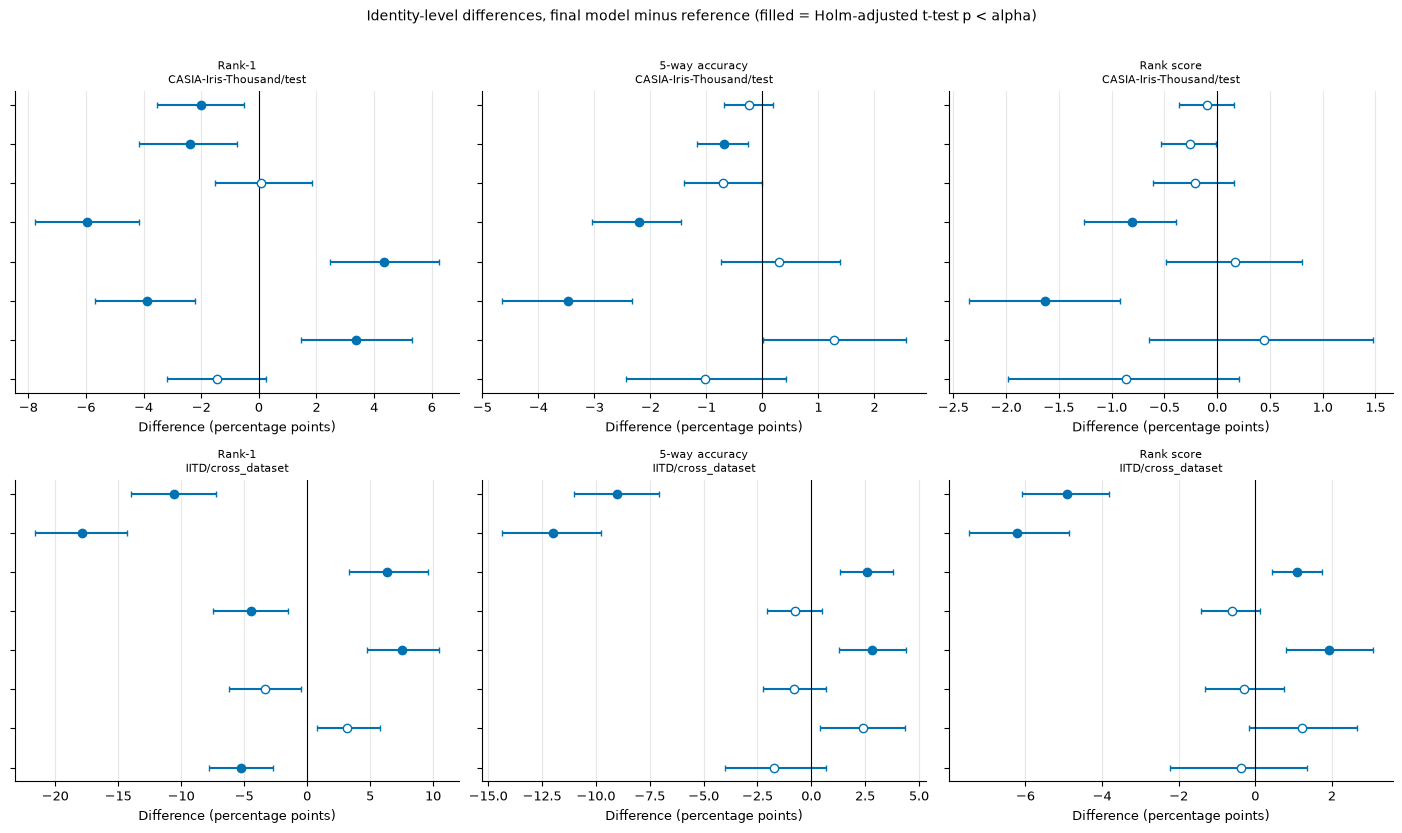

Saved: fig_forest_identity_level


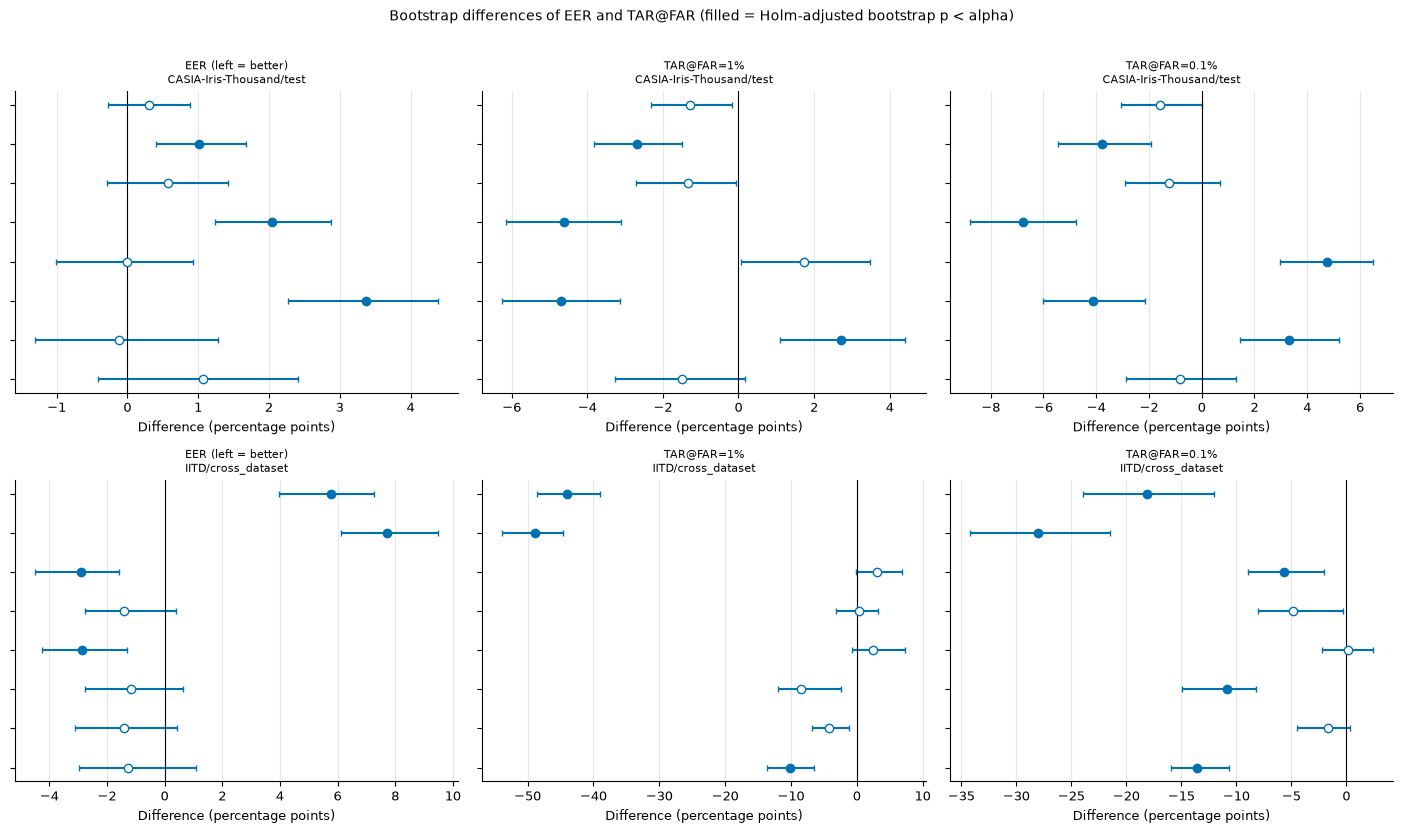

Saved: fig_forest_bootstrap


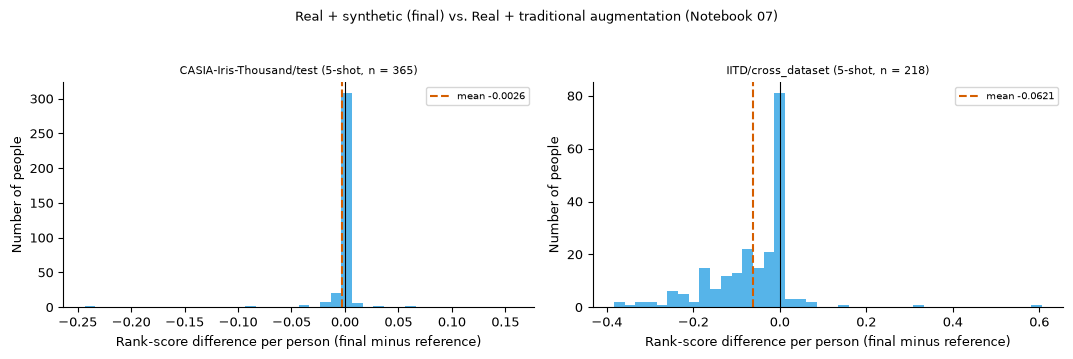

Saved: fig_identity_difference_distribution


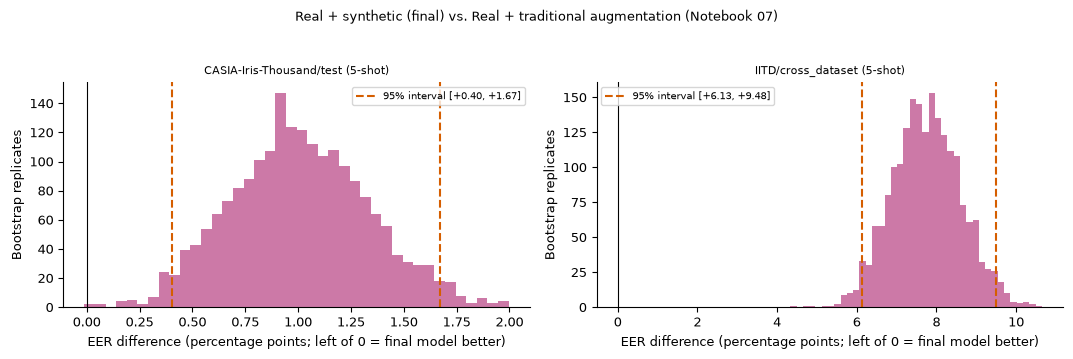

Saved: fig_bootstrap_eer_difference


In [13]:
# ============================================================
# 12. Figures
# ============================================================

plt.rcParams.update({"font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 7, "figure.dpi": 100,
                     "savefig.dpi": FIGURE_DPI, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})
FIGURE_NAMES = []


def save_figure(fig, name):
    for fmt in FIGURE_FORMATS:
        fig.savefig(FIG_DIR / f"{name}.{fmt}", dpi=FIGURE_DPI, bbox_inches="tight")
    FIGURE_NAMES.append(name)
    plt.show()
    plt.close(fig)
    print("Saved:", name)


def forest_plot(df, metrics, diff_column, p_column, title, name):
    df = df[df["metric"].isin(metrics)]
    if len(df) == 0:
        print(f"No data for '{name}'; skipped.")
        return
    sets_here = [s for s in eval_sets if s in set(df["eval_set"])]
    labels = list(dict.fromkeys(f"{r.comparison} | {int(r.shot)}-shot" for r in df.itertuples()))
    labels = sorted(labels, key=lambda s: (s.rsplit("| ", 1)[1], s))
    height = 0.34 * len(labels) + 1.5
    fig, axes = plt.subplots(len(sets_here), len(metrics), figsize=(3.7 * len(metrics) + 3.0, height * len(sets_here)), squeeze=False, sharey=True)

    for r_index, eval_set in enumerate(sets_here):
        for c_index, metric in enumerate(metrics):
            ax = axes[r_index, c_index]
            sub = df[(df["eval_set"] == eval_set) & (df["metric"] == metric)]
            scale = 100.0 if metric != "x" else 1.0
            for row in sub.itertuples():
                label = f"{row.comparison} | {int(row.shot)}-shot"
                y = labels.index(label)
                diff, low, high = getattr(row, diff_column) * scale, row.ci_low * scale, row.ci_high * scale
                significant = bool(getattr(row, p_column) < ALPHA)
                ax.errorbar(diff, y, xerr=[[diff - low], [high - diff]], fmt="o", color="#0072B2", markerfacecolor="#0072B2" if significant else "white", capsize=2)
            ax.axvline(0.0, color="black", linewidth=0.8)
            ax.set_yticks(range(len(labels)))
            ax.set_yticklabels([textwrap.shorten(l, 70) for l in labels] if c_index == 0 else [], fontsize=6)
            ax.set_xlabel("Difference (percentage points)")
            ax.set_title(f"{METRIC_LABELS[metric]}{' (left = better)' if metric == 'eer' else ''}\n{eval_set}", fontsize=8)
            ax.grid(axis="x", alpha=0.3)

    fig.suptitle(title, fontsize=10)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    save_figure(fig, name)


if len(identity_tests):
    forest_plot(identity_tests, ["rank1", "acc5", "rank_score"], "mean_diff", "p_t_holm",
                "Identity-level differences, final model minus reference (filled = Holm-adjusted t-test p < alpha)", "fig_forest_identity_level")
if len(pooled_tests):
    forest_plot(pooled_tests, ["eer"] + [tar_key(f) for f in FAR_TARGETS], "diff", "p_bootstrap_holm",
                "Bootstrap differences of EER and TAR@FAR (filled = Holm-adjusted bootstrap p < alpha)", "fig_forest_bootstrap")

# ---- distribution of the per-identity differences, and the bootstrap of the EER difference, for the main comparison ----
main = next((c for c in comparison_plan if c[0] == "final_real_plus_synthetic" and c[1] == "baseline_traditional_aug"), comparison_plan[0])
main_a, main_b = main[0], main[1]
main_shot = max(s for a, b, s in comparison_plan if (a, b) == (main_a, main_b))
sets_main = [e for e in eval_sets if run_stats(main_a, main_shot, e) and run_stats(main_b, main_shot, e)]

if sets_main:
    fig, axes = plt.subplots(1, len(sets_main), figsize=(5.4 * len(sets_main), 3.6), squeeze=False)
    for ax, eval_set in zip(axes[0], sets_main):
        stats_a, stats_b = run_stats(main_a, main_shot, eval_set), run_stats(main_b, main_shot, eval_set)
        valid = stats_a[0]["valid"]
        d = (np.mean([s["rank_score_i"] for s in stats_a], axis=0) - np.mean([s["rank_score_i"] for s in stats_b], axis=0))[valid]
        d = d[np.isfinite(d)]
        ax.hist(d, bins=40, color="#56B4E9")
        ax.axvline(0.0, color="black", linewidth=0.8)
        ax.axvline(float(d.mean()), color="#D55E00", linestyle="--", label=f"mean {d.mean():+.4f}")
        ax.set_xlabel("Rank-score difference per person (final minus reference)")
        ax.set_ylabel("Number of people")
        ax.set_title(f"{eval_set} ({main_shot}-shot, n = {len(d)})", fontsize=8)
        ax.legend()
    fig.suptitle(f"{comparison_name(main_a, main_b)}", fontsize=9)
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    save_figure(fig, "fig_identity_difference_distribution")

    fig, axes = plt.subplots(1, len(sets_main), figsize=(5.4 * len(sets_main), 3.6), squeeze=False)
    for ax, eval_set in zip(axes[0], sets_main):
        reps = 100.0 * (BOOT[(main_shot, eval_set, main_a)]["eer"] - BOOT[(main_shot, eval_set, main_b)]["eer"])
        observed = pooled_tests[(pooled_tests["a_group"] == main_a) & (pooled_tests["b_group"] == main_b) & (pooled_tests["shot"] == main_shot)
                                & (pooled_tests["eval_set"] == eval_set) & (pooled_tests["metric"] == "eer")]
        ax.hist(_finite(reps), bins=40, color="#CC79A7")
        ax.axvline(0.0, color="black", linewidth=0.8)
        if len(observed):
            low, high = 100 * observed["ci_low"].iloc[0], 100 * observed["ci_high"].iloc[0]
            ax.axvline(low, color="#D55E00", linestyle="--")
            ax.axvline(high, color="#D55E00", linestyle="--", label=f"95% interval [{low:+.2f}, {high:+.2f}]")
        ax.set_xlabel("EER difference (percentage points; left of 0 = final model better)")
        ax.set_ylabel("Bootstrap replicates")
        ax.set_title(f"{eval_set} ({main_shot}-shot)", fontsize=8)
        ax.legend()
    fig.suptitle(f"{comparison_name(main_a, main_b)}", fontsize=9)
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    save_figure(fig, "fig_bootstrap_eer_difference")

## 13. Sanity checks

**Stop the notebook if:**
- a model was not scored, or the models of a shot did not see the same probes and identities;
- the re-computed Rank-1 or EER differs from Notebook 14's stored value by more than 0.01 (the pipeline would then not be the one that produced the reported numbers);
- a p-value lies outside `[0, 1]`, a Holm-adjusted p-value is below its raw p-value, or an interval has its ends reversed;
- no identity-level test was produced, or a saved file is missing.

**Warn if** (these describe expected behaviour, not guaranteed behaviour):
- the re-computed values differ from Notebook 14's by more than 0.001 (small GPU or precision differences);
- the expected 5-way accuracy differs from Notebook 14's Monte Carlo value by more than 0.02;
- a histogram-based EER differs from the exact one by more than 0.005;
- the bootstrap interval of a difference does not contain the observed difference;
- fewer than 30 identities are compared (the normal approximation and the bootstrap are rough);
- only one seed exists (no seed-level tests), or fewer than 6 (Wilcoxon cannot reach p < 0.05 with 5 or fewer pairs);
- the final model is **not** significantly better than a reference (**a result, not an error**).

In [14]:
# ============================================================
# 13. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


expected_keys = {(r["run_id"], e) for r in run_list for e in eval_sets if pool_rows(e, r["shot"]) is not None}
add_check("every selected model was scored on every evaluation set", expected_keys == set(POOL_STATS), f"{len(expected_keys - set(POOL_STATS))} missing")
add_check("all models of a shot saw the same probes and identities (the pairing needs it)", not misaligned, f"{len(misaligned)} misaligned")

# ---- agreement with the numbers stored by Notebook 14 ----
stored = results14[["run_id", "eval_set", "rank1_acc", "eer", "acc_5way"]]
rows = []
for (run_id, eval_set), stats in POOL_STATS.items():
    match = stored[(stored["run_id"] == run_id) & (stored["eval_set"] == eval_set)]
    if len(match):
        rows.append({"run_id": run_id, "eval_set": eval_set, "d_rank1": abs(stats["exact"]["rank1"] - float(match["rank1_acc"].iloc[0])),
                     "d_eer": abs(stats["exact"]["eer"] - float(match["eer"].iloc[0])),
                     "d_acc5": abs(stats["exact"]["acc5"] - float(match["acc_5way"].iloc[0])) if np.isfinite(stats["exact"]["acc5"]) else np.nan})
agreement = pd.DataFrame(rows)

if len(agreement):
    worst = float(max(agreement["d_rank1"].max(), agreement["d_eer"].max()))
    add_check("the re-computed Rank-1 and EER agree with Notebook 14 (largest difference below 0.01)", worst < 0.01, f"largest difference {worst:.2e} over {len(agreement)} results")
    add_check("the agreement is within 0.001 (no GPU or precision drift)", worst < 0.001, f"largest difference {worst:.2e}", critical=False)
    worst_acc5 = float(np.nanmax(agreement["d_acc5"])) if np.isfinite(agreement["d_acc5"]).any() else 0.0
    add_check("the expected 5-way accuracy matches Notebook 14's Monte Carlo value (within 0.02)", worst_acc5 < 0.02, f"largest difference {worst_acc5:.3f}", critical=False)
else:
    add_check("the re-computed metrics could be compared with Notebook 14", False, "no matching rows in cross_dataset_results.csv")

hist_gap = max((abs(weighted_hist_metrics(s, s["valid"].astype(np.float32))["eer"] - s["exact"]["eer"]) for s in POOL_STATS.values()), default=0.0)
add_check("the histogram EER is within 0.005 of the exact EER (HIST_BINS is fine enough)", hist_gap < 0.005, f"largest gap {hist_gap:.4f}", critical=False)

# ---- the test tables ----
add_check("at least one identity-level test was produced", len(identity_tests) > 0)
all_tables = [t for t in (identity_tests, pooled_tests, seed_tests, ablation_tests) if len(t)]
p_columns = [c for t in all_tables for c in t.columns if c.startswith("p_")]
valid_p = all(bool(((t[c].dropna() >= 0) & (t[c].dropna() <= 1)).all()) for t in all_tables for c in t.columns if c.startswith("p_"))
add_check("every p-value lies in [0, 1]", valid_p, f"{len(p_columns)} p columns checked")

holm_ok = all(bool((t[c + "_holm"].dropna() + 1e-12 >= t[c].loc[t[c + "_holm"].dropna().index]).all())
              for t in all_tables for c in t.columns if c.startswith("p_") and not c.endswith("_holm") and c + "_holm" in t.columns)
add_check("no Holm-adjusted p-value is below its raw p-value", holm_ok)

reversed_ci = sum(int((t["ci_low"] > t["ci_high"]).sum()) for t in all_tables if "ci_low" in t.columns)
add_check("every confidence interval has its ends in order", reversed_ci == 0, f"{reversed_ci} reversed")

if len(pooled_tests):
    outside = int((~((pooled_tests["ci_low"] - 1e-9 <= pooled_tests["diff"]) & (pooled_tests["diff"] <= pooled_tests["ci_high"] + 1e-9))).sum())
    add_check("the bootstrap interval of each pooled difference contains the observed difference", outside == 0, f"{outside} of {len(pooled_tests)} do not", critical=False)

if len(identity_tests):
    small = identity_tests[identity_tests["n_identities"] < 30]
    add_check("at least 30 identities in every comparison", len(small) == 0, f"{len(small)} test(s) with fewer", critical=False)

seeds_per_model = pd.DataFrame(run_list).groupby(["shot", "group"])["seed"].nunique()
add_check("at least two seeds per model (seed-level tests possible)", bool((seeds_per_model >= 2).all()),
          f"{int((seeds_per_model < 2).sum())} of {len(seeds_per_model)} models have one seed", critical=False)
add_check("at least 6 seeds (the Wilcoxon test can reach p < 0.05 only with 6 or more pairs)", bool((seeds_per_model >= 6).all()),
          f"largest number of seeds: {int(seeds_per_model.max())}", critical=False)

for column, table, label in [("p_t_holm", identity_tests, "identity-level t-test"), ("p_bootstrap_holm", pooled_tests, "bootstrap")]:
    if len(table):
        for reference, group in table.groupby("b_group"):
            focus = group[group["metric"].isin(["rank1", "eer"])]
            not_sig = focus[~(focus[column] < ALPHA)]
            add_check(f"the final model is significantly better than {GROUP_LABELS.get(reference, reference)} ({label}; a result, not an error)",
                      len(not_sig) == 0, f"{len(not_sig)} of {len(focus)} Rank-1 / EER comparisons are not significant", critical=False)

written = [n for n in ["identity_level_tests", "bootstrap_pooled_metrics", "seed_level_tests", "ablation_seed_tests"] if not (TABLE_DIR / f"{n}.csv").exists()]
add_check("every results table was written", not written, f"missing: {written}")

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "statistical_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "statistical_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical statistical checks failed: {failed_names}"
print("\nStatistical sanity checks completed with no critical failures.")

[PASS] every selected model was scored on every evaluation set  (0 missing)
[PASS] all models of a shot saw the same probes and identities (the pairing needs it)  (0 misaligned)
[PASS] the re-computed Rank-1 and EER agree with Notebook 14 (largest difference below 0.01)  (largest difference 9.71e-17 over 24 results)
[PASS] the agreement is within 0.001 (no GPU or precision drift)  (largest difference 9.71e-17)
[PASS] the expected 5-way accuracy matches Notebook 14's Monte Carlo value (within 0.02)  (largest difference 0.010)
[PASS] the histogram EER is within 0.005 of the exact EER (HIST_BINS is fine enough)  (largest gap 0.0006)
[PASS] at least one identity-level test was produced
[PASS] every p-value lies in [0, 1]  (8 p columns checked)
[PASS] no Holm-adjusted p-value is below its raw p-value
[PASS] every confidence interval has its ends in order  (0 reversed)
[PASS] the bootstrap interval of each pooled difference contains the observed difference  (0 of 112 do not)
[PASS] at least 

## 14. Final outputs

At the end of Notebook 18, the project should contain:

```text
results/statistical_analysis/
├── tables/
│   ├── identity_level_tests.csv           paired t-test, Wilcoxon, bootstrap, Cohen's d (per-person differences)
│   ├── bootstrap_pooled_metrics.csv       EER, TAR@FAR, ROC-AUC, Rank-1, 5-way: differences with bootstrap intervals
│   ├── seed_level_tests.csv               tests over training seeds (needs several seeds)
│   ├── ablation_seed_tests.csv            the same for the Notebook 16 arms (optional)
│   └── table_significance_summary.csv / .md / .tex      the table for the paper
├── figures/ (.png and .pdf)
│   ├── fig_forest_identity_level, fig_forest_bootstrap
│   └── fig_identity_difference_distribution, fig_bootstrap_eer_difference
└── statistical_sanity_checks.csv
```

In [15]:
# ============================================================
# 14. Final output listing
# ============================================================

print("Notebook 18 output directory:")
print(RESULTS_DIR)

for folder in (TABLE_DIR, FIG_DIR):
    print(f"\n{folder.name}/")
    for path in sorted(folder.iterdir()):
        print(f"- {path.name}")

print(f"\nIdentity-level tests: {len(identity_tests)} | bootstrap rows: {len(pooled_tests)} | seed-level rows: {len(seed_tests)} | "
      f"ablation rows: {len(ablation_tests)} | figures: {len(FIGURE_NAMES)}")
print("\nNotebook 18 completed.")

Notebook 18 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\statistical_analysis

tables/
- ablation_seed_tests.csv
- bootstrap_pooled_metrics.csv
- identity_level_tests.csv
- seed_level_tests.csv
- table_significance_summary.csv
- table_significance_summary.md
- table_significance_summary.tex

figures/
- fig_bootstrap_eer_difference.pdf
- fig_bootstrap_eer_difference.png
- fig_forest_bootstrap.pdf
- fig_forest_bootstrap.png
- fig_forest_identity_level.pdf
- fig_forest_identity_level.png
- fig_identity_difference_distribution.pdf
- fig_identity_difference_distribution.png

Identity-level tests: 48 | bootstrap rows: 112 | seed-level rows: 0 | ablation rows: 0 | figures: 4

Notebook 18 completed.


## 15. How to report the results

```text
Notebooks 14, 16, 17           Notebook 18                      the paper
Results of every model  --->   Tests, intervals, effect sizes ---> experimental section
```

### What to write

For a comparison of the final model with a reference, report the **difference with its 95% interval**, the **adjusted p-value**, and the **effect size**, for example:

> "On the unseen dataset, the final model lowers the EER by 1.2 percentage points relative to traditional augmentation (95% bootstrap interval [0.4, 2.0], Holm-adjusted p = 0.01). The Rank-1 gain per person is small to medium (Cohen's d_z = 0.35; paired t-test and Wilcoxon, Holm-adjusted p < 0.001)."

### Rules

1. **State the unit of the test.** Identity-level tests generalise to new people for the trained models; only seed-level tests speak about training randomness. With one seed, say so.
2. **Report intervals and effect sizes, not only p-values.** With a few hundred people, a tiny difference can be significant, and a large one can be insignificant.
3. **Report the correction.** All p-values here are Holm-adjusted within each metric; state the number of comparisons.
4. **Do not tune on these results.** Models were chosen with the validation people only; do not switch models or settings after seeing a significance level.
5. **Name every reference**, including traditional augmentation: a gain over real-only training alone is weak evidence for the generator.
6. A non-significant result is a result. Report it, with its interval.

### Reading the tables

| What you see | Meaning | What to do |
|---|---|---|
| t-test and Wilcoxon agree, interval excludes 0 | A consistent per-person gain | Report it with the effect size |
| t-test significant, Wilcoxon not (or the reverse) | A few people drive the mean, or the differences are skewed | Look at `fig_identity_difference_distribution` before claiming |
| Rank-1 not significant, EER significant | The gain is in verification, not in identification | Report both |
| Significant on the test people, not on the unseen dataset | The gain does not transfer; the unseen dataset also has fewer people | Look at the interval width, not only the p-value |
| Seed-level p never below 0.05 with 5 seeds | The Wilcoxon test cannot reach it with so few pairs | Use more seeds, or rely on the interval of the t-test and the effect size |
| Huge effect size, tiny interval | Check for leakage or a mismatch between models | Re-run the sanity checks; compare the re-computed numbers with Notebook 14 |